# 🔬 EDA для ISIC 2018 Task 1 — Training Set Only (ENHANCED)

**Датасет:** [ISIC 2018 Challenge Task 1](https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation)

**Задача:** Бинарная сегментация границ кожных поражений (меланома)

## 📊 Анализ только TRAINING набора — расширенная версия

### 🆕 Добавлено по сравнению с базовой версией:
1. 📥 Загрузка и подготовка данных
2. 📊 Извлечение метрик из training набора
3. 🎨 Визуализация примеров
4. 📈 Анализ распределений
5. 🔍 Детектирование дубликатов (с визуализацией)
6. 💾 Экспорт в CSV файлы
7. 🚀 Рекомендации для TransUNet
8. 🆕 **Pixel-Level Class Imbalance (точный подсчёт + α/pos_weight)**
9. 🆕 **Multi-Scale Analysis (128, 256, 512)**
10. 🆕 **Hard Examples Mining (4 критерия + CSV)**
11. 🆕 **Correlation Matrix (heatmap ключевых метрик)**

In [45]:
# Установка зависимостей
!pip install -q pillow opencv-python matplotlib seaborn pandas numpy kagglehub tqdm

In [46]:
# Импорт библиотек
import os
import glob
import random
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from PIL import Image
import cv2
from tqdm.auto import tqdm
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# --- dhash (difference hash) для детектирования near-duplicates ---
def _compute_dhash(img_cv, hash_size=8):
    """Difference hash: устойчив к небольшому изменению яркости/сжатия.
    Возвращает 64-битный хеш как hex-строку."""
    gray = cv2.cvtColor(img_cv, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, (hash_size + 1, hash_size))
    diff = resized[:, 1:] > resized[:, :-1]  # построчное сравнение
    return ''.join(str(int(b)) for b in diff.flatten())

def _hamming_distance(h1, h2):
    """Расстояние Хэмминга для двух dhash строк одинаковой длины."""
    return sum(c1 != c2 for c1, c2 in zip(h1, h2))

# Настройка визуализации
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (15, 10)
plt.rcParams['font.size'] = 11

# Генератор случайных чисел с фиксированным seed для воспроизводимости
rng = random.Random(42)
print("✅ Все библиотеки загружены!")

✅ Все библиотеки загружены!


## 1️⃣ Загрузка датасета

In [47]:
# Загрузка датасета
path = kagglehub.dataset_download("tschandl/isic2018-challenge-task1-data-segmentation")
print(f"✅ Датасет загружен: {path}")

# Пути к TRAINING данным
train_img_dir = os.path.join(path, "ISIC2018_Task1-2_Training_Input")
train_mask_dir = os.path.join(path, "ISIC2018_Task1_Training_GroundTruth")

# Поиск всех изображений
train_imgs = sorted(glob.glob(os.path.join(train_img_dir, "*.jpg")))

print(f"\n📂 Структура:")
print(f"  Train Images: {len(train_imgs)} файлов")
print(f"  Train Masks:  {len(glob.glob(os.path.join(train_mask_dir, '*.png')))} файлов")

✅ Датасет загружен: /home/dzmitry_tsetsiaruk/.cache/kagglehub/datasets/tschandl/isic2018-challenge-task1-data-segmentation/versions/1

📂 Структура:
  Train Images: 2594 файлов
  Train Masks:  2594 файлов


## 2️⃣ Функция извлечения метрик

> **Категории метрик:**
> - 🔴 **Геометрия маски (segmentation core):** mask_area_ratio, compactness, lesion_aspect_ratio, centroid_*, touches_border, n_holes, noise_islands_count, boundary_*, edge_*


In [48]:
# Унифицированная обёртка для совместимости OpenCV 3.x/4.x
def _find_contours(mask_bin, mode):
    """Возвращает (contours, hierarchy) из cv2.findContours независимо от версии OpenCV."""
    result = cv2.findContours(mask_bin, mode, cv2.CHAIN_APPROX_SIMPLE)
    # OpenCV 4: (image, contours, hierarchy) → len=3
    # OpenCV 3: (contours, hierarchy)       → len=2
    if len(result) == 3:
        return result[1], result[2]  # contours, hierarchy
    return result[0], result[1]      # contours, hierarchy
def extract_metrics(img_path, mask_path):
    """Извлекает 30+ метрик из пары изображение-маска.
    
    Категории:
      - Геометрия маски: area, compactness, holes, contours, boundaries (segmentation core)
      - Appearance: RGB, HSV-контраст, hair_score (EDA only — в модель НЕ подавать)
    """
    try:
        base_name = os.path.basename(img_path)
        name_without_ext = os.path.splitext(base_name)[0]
        
        # Размеры изображения
        with Image.open(img_path) as img:
            w, h = img.size
        
        # Чтение маски
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            return None
        
        # ---- Геометрия маски (segmentation core) ----
        
        # Базовые метрики маски
        total_pixels = mask.size
        white_pixels = np.sum(mask > 127)
        mask_area_ratio = white_pixels / total_pixels
        is_mask_empty = 1 if white_pixels == 0 else 0
        
        # Бинарность маски
        uniq_vals = np.unique(mask)
        is_strict_binary = bool(set(uniq_vals.tolist()).issubset({0, 255}))
        intermediate_px_ratio = float(np.mean((mask > 0) & (mask < 255)))
        
        # Центроид и касание границ
        if white_pixels > 0:
            ys, xs = np.where(mask > 127)
            centroid_x_norm = xs.mean() / w
            centroid_y_norm = ys.mean() / h
            touches_border = int(
                xs.min() <= 2 or ys.min() <= 2 or
                xs.max() >= w - 3 or ys.max() >= h - 3
            )
            
            # Компактность
            mask_binary = (mask > 127).astype(np.uint8)
            contours, _ = _find_contours(mask_binary, cv2.RETR_EXTERNAL)
            if contours:
                largest_contour = max(contours, key=cv2.contourArea)
                area = cv2.contourArea(largest_contour)
                perimeter = cv2.arcLength(largest_contour, True)
                compactness = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0
                
                # Aspect ratio опухоли
                rect = cv2.minAreaRect(largest_contour)
                width_rect, height_rect = rect[1]
                lesion_aspect_ratio = max(width_rect, height_rect) / (min(width_rect, height_rect) + 1e-6)
            else:
                compactness = 0
                lesion_aspect_ratio = 1
        else:
            centroid_x_norm, centroid_y_norm, touches_border = np.nan, np.nan, 0
            compactness = 0
            lesion_aspect_ratio = 1
        
        # Контуры и дырки
        contours_ext, _ = _find_contours(mask_binary, cv2.RETR_EXTERNAL)
        noise_islands_count = len(contours_ext)
        
        # Дырки: RETR_CCOMP — hierarchy[-1] всегда hierarchy в OpenCV 3 и 4
        _, hierarchy = _find_contours(mask, cv2.RETR_CCOMP)
        n_holes = sum(1 for row in hierarchy[0] if row[3] != -1) if hierarchy is not None else 0
        
        # ---- Appearance-метрики (EDA only, в модель НЕ подавать) ----
        # Эти метрики извлекаются из самого изображения (не leak), но описывают
        # цвет/текстуру, а не геометрию маски. Модель сегментации учится из пикселей.
        # Подавать их можно только в multi-task (seg + classification).
        
        img_cv = cv2.imread(img_path)
        # RGB статистики (appearance)
        img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        
        r_mean, g_mean, b_mean = img_rgb.mean(axis=(0, 1))
        r_std, g_std, b_std = img_rgb.std(axis=(0, 1))
        
        # dhash (difference hash) — устойчив к JPEG-рекомпрессии и изменению яркости.
        # Детектирует near-duplicates. Порог Хэмминга ≤ 5 считает изображения дубликатами.
        dhash = _compute_dhash(img_cv)
        
        # Контраст опухоль/кожа в HSV (appearance, EDA only)
        img_hsv = cv2.cvtColor(img_cv, cv2.COLOR_BGR2HSV)
        v_channel = img_hsv[:, :, 2]
        
        lesion_mean = np.mean(v_channel[mask > 127]) if white_pixels > 0 else 0
        skin_mean = np.mean(v_channel[mask <= 127]) if (total_pixels - white_pixels) > 0 else 0
        contrast = abs(lesion_mean - skin_mean)
        
        # Индекс текстуры/шума (appearance, EDA only — прокси, не детектор волос).
        # ⚠️ ПРИМЕЧАНИЕ: std Лапласиана после Gaussian blur измеряет ОБЩУЮ текстуру изображения,
        # а не специфично волосы. Артефакты сжатия, неровная кожа, пузырьки тоже дают высокий
        # отклик. Для точного детектора волос используйте DullRazor или морфологический метод.
        hair_score = np.std(cv2.Laplacian(cv2.GaussianBlur(img_cv, (5, 5), 0), cv2.CV_64F))
        
        # 🆕 Граничные метрики (Boundary Analysis)
        if white_pixels > 0:
            mask_bin = (mask > 127).astype(np.uint8)
            # Boundary mask: dilation - erosion
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
            dilated = cv2.dilate(mask_bin, kernel, iterations=1)
            eroded = cv2.erode(mask_bin, kernel, iterations=1)
            boundary_mask = dilated - eroded
            # Переводим изображение в grayscale для вычисления градиента ВДОЛЬ ГРАНИЦЫ
            img_gray = cv2.cvtColor(img_cv, cv2.COLOR_BGR2GRAY).astype(np.float32)
            boundary_pixels = np.sum(boundary_mask > 0)
            boundary_thickness_ratio = boundary_pixels / max(white_pixels, 1)
            
            # Edge smoothness & mean gradient: вычисляем градиент ИЗОБРАЖЕНИЯ вдоль контура маски.
            # Ранее был баг: градиент считался по бинарной маске (всегда ≈1), а не по изображению.
            # Теперь используется img_gray — градиент интенсивности кожи/поражения на границе.
            grad_x = cv2.Sobel(img_gray, cv2.CV_32F, 1, 0, ksize=3)
            grad_y = cv2.Sobel(img_gray, cv2.CV_32F, 0, 1, ksize=3)
            grad_mag = np.sqrt(grad_x**2 + grad_y**2)
            edge_smoothness = np.std(grad_mag[boundary_mask > 0]) if boundary_pixels > 0 else 0
            edge_mean_gradient = np.mean(grad_mag[boundary_mask > 0]) if boundary_pixels > 0 else 0
        else:
            boundary_thickness_ratio = 0
            edge_smoothness = 0
            edge_mean_gradient = 0
        
        return {
            "file_stem": name_without_ext,
            "orig_width": w,
            "orig_height": h,
            "aspect_ratio": w / h,
            "mask_area_ratio": mask_area_ratio,
            "is_mask_empty": is_mask_empty,
            "noise_islands_count": noise_islands_count,
            "n_holes": n_holes,
            "lesion_skin_contrast": contrast,
            "hair_noise_score": hair_score,
            "is_strict_binary_mask": is_strict_binary,
            "intermediate_px_ratio": intermediate_px_ratio,
            "centroid_x_norm": centroid_x_norm,
            "centroid_y_norm": centroid_y_norm,
            "touches_border": touches_border,
            "compactness": compactness,
            "lesion_aspect_ratio": lesion_aspect_ratio,
            "r_mean": r_mean, "g_mean": g_mean, "b_mean": b_mean,
            "r_std": r_std, "g_std": g_std, "b_std": b_std,
            "dhash": dhash,
            "img_path": img_path,
            "mask_path": mask_path,
            # 🆕 Boundary metrics
            "boundary_thickness_ratio": boundary_thickness_ratio,
            "edge_smoothness": edge_smoothness,
            "edge_mean_gradient": edge_mean_gradient,
        }
    except (cv2.error, OSError, ValueError) as e:
        print(f"⚠️ Ошибка: {img_path}: {e}")
        return None

## 3️⃣ Обработка Training набора

In [49]:
# ==========================================
# НАСТРОЙКА КЭШИРОВАНИЯ (по образцу EDA-classificariob)
# ==========================================
import pickle

NOTEBOOK_DIR = Path.cwd()
PROCESSED_DIR = str(NOTEBOOK_DIR / '..' / 'data' / 'processed')
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Кэш-файлы
CACHE_TRAIN_CSV = os.path.join(PROCESSED_DIR, "isic2018_train_eda_report.csv")
CACHE_MULTISCALE = os.path.join(PROCESSED_DIR, "isic2018_multiscale_analysis.csv")
CACHE_HARD_EXAMPLES = os.path.join(PROCESSED_DIR, "isic2018_hard_examples.csv")

def save_cache(obj, path, format='csv'):
    """Сохранить объект в кэш."""
    os.makedirs(os.path.dirname(path) if os.path.dirname(path) else PROCESSED_DIR, exist_ok=True)
    if format == 'csv' and isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    elif format == 'npy':
        np.save(path, obj)
    elif format == 'pkl':
        with open(path, 'wb') as f:
            pickle.dump(obj, f)
    print(f"💾 Кэш сохранён: {path}")

def load_cache(path, format='csv'):
    """Загрузить объект из кэша. Возвращает None если файл отсутствует."""
    if not os.path.exists(path):
        return None
    if format == 'csv':
        print(f"📂 Загружен кэш: {path}")
        return pd.read_csv(path)
    elif format == 'npy':
        print(f"📂 Загружен кэш: {path}")
        return np.load(path, allow_pickle=True)
    elif format == 'pkl':
        with open(path, 'rb') as f:
            print(f"📂 Загружен кэш: {path}")
            return pickle.load(f)
    return None

print("✅ Система кэширования готова.")
print(f"   Директория кэша: {PROCESSED_DIR}")
print(f"   Основной отчёт:  {CACHE_TRAIN_CSV}")
print(f"   Multi-scale:     {CACHE_MULTISCALE}")
print(f"   Hard examples:   {CACHE_HARD_EXAMPLES}")


✅ Система кэширования готова.
   Директория кэша: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed
   Основной отчёт:  /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_train_eda_report.csv
   Multi-scale:     /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_multiscale_analysis.csv
   Hard examples:   /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_hard_examples.csv


In [50]:
# ==========================================
# ОБРАБОТКА TRAINING НАБОРА (с кэшированием)
# ==========================================

# Пытаемся загрузить из кэша
df_train_cached = load_cache(CACHE_TRAIN_CSV, format='csv')

if df_train_cached is not None:
    df_train = df_train_cached
    missing_mask = []
    broken_files = []
    # Восстанавливаем списки для отчета из кэшированного датафрейма
    if 'is_mask_empty' in df_train.columns:
        broken_count = ((df_train['is_mask_empty'] == 0) & (df_train['mask_area_ratio'] == 0)).sum()
        if broken_count > 0:
            broken_files = df_train.loc[
                (df_train['is_mask_empty'] == 0) & (df_train['mask_area_ratio'] == 0), 'file_stem'
            ].tolist()
    print(f"   Записей в кэше: {len(df_train)}")
else:
    print("\n🔄 Обработка training набора (первый запуск — без кэша)...\n")

    records = []
    missing_mask = []
    broken_files = []

    for img_path in tqdm(train_imgs, desc="Анализ изображений"):
        base_name = os.path.basename(img_path)
        name_without_ext = os.path.splitext(base_name)[0]
        mask_path = os.path.join(train_mask_dir, f"{name_without_ext}_segmentation.png")

        if not os.path.exists(mask_path):
            missing_mask.append(base_name)
            continue

        metrics = extract_metrics(img_path, mask_path)
        if metrics:
            records.append(metrics)
        else:
            broken_files.append(base_name)

    # Создание DataFrame
    df_train = pd.DataFrame(records)

    print(f"\n✅ Обработка завершена:")
    print(f"   Успешно: {len(df_train)} изображений")
    print(f"   Пропущено (нет маски): {len(missing_mask)}")
    print(f"   Битых файлов: {len(broken_files)}")

    # Сохраняем в кэш
    save_cache(df_train, CACHE_TRAIN_CSV, format='csv')

# Сохраняем missing/broken в PROCESSED_DIR
if len(missing_mask) > 0 or len(broken_files) > 0:
    missing_df = pd.DataFrame({
        'filename': missing_mask + broken_files,
        'reason': ['Missing mask'] * len(missing_mask) + ['Broken file'] * len(broken_files)
    })
    missing_df.to_csv(os.path.join(PROCESSED_DIR, 'isic2018_train_missing_files.csv'), index=False)
    print(f"💾 Отчёт о пропущенных сохранён: {os.path.join(PROCESSED_DIR, 'isic2018_train_missing_files.csv')}")
else:
    print("✅ Все файлы в порядке, пропущенных нет")


📂 Загружен кэш: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_train_eda_report.csv
   Записей в кэше: 2594
✅ Все файлы в порядке, пропущенных нет


In [51]:
# Локальная копия основного отчёта для быстрого доступа
# (основной кэш в PROCESSED_DIR уже сохранён в ячейке обработки)
local_csv = 'isic2018_train_eda_report.csv'
if not os.path.exists(local_csv):
    df_train.to_csv(local_csv, index=False)
print(f"📂 Локальная копия: {local_csv}")
print(f"📂 Основной кэш:    {CACHE_TRAIN_CSV}")


📂 Локальная копия: isic2018_train_eda_report.csv
📂 Основной кэш:    /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_train_eda_report.csv


## 5️⃣ Базовая статистика

> **ℹ️ Ограничения метрик:**
> - 🟡 **Appearance-метрики** (`r/g/b_mean/std`, `lesion_skin_contrast`, `hair_noise_score`) — для EDA only. Вычислены из изображения (не leak), но описывают цвет/текстуру, а не геометрию маски. В модель сегментации подавать **не надо** (только в multi-task: seg+cls).
> - `hair_noise_score` — std Лапласиана после Gaussian blur. Это **прокси** общей текстуры изображения, а не детектор волос. Артефакты сжатия, неровная кожа, пузырьки тоже дают высокий отклик. Для точного детектора волос используйте DullRazor.
> - `dhash` — difference hash 64 бита. Детектирует **near-duplicates** (устойчив к JPEG-рекомпрессии, небольшому изменению яркости). Порог Хэмминга ≤ 5 — дубликат.


In [52]:
# Фильтруем валидные маски
valid_masks = df_train[df_train['mask_area_ratio'] > 0].dropna(subset=['centroid_x_norm', 'centroid_y_norm'])

print("\n" + "="*80)
print("📊 СТАТИСТИКА TRAINING НАБОРА")
print("="*80)

print(f"\n1️⃣ Общие данные:")
print(f"   • Всего изображений: {len(df_train)}")
print(f"   • Валидных масок: {len(valid_masks)} ({len(valid_masks)/len(df_train)*100:.1f}%)")
print(f"   • Пустых масок: {df_train['is_mask_empty'].sum()}")

print(f"\n2️⃣ Разрешения:")
# Сбрасываем колонку resolution если уже существует (re-run safety)
if 'resolution' in df_train.columns:
    df_train = df_train.drop(columns=['resolution'])
df_train['resolution'] = df_train['orig_width'].astype(str) + 'x' + df_train['orig_height'].astype(str)
top_res = df_train['resolution'].value_counts().head(5)
print(f"   • Уникальных разрешений: {df_train['resolution'].nunique()}")
for res, count in top_res.items():
    print(f"   • {res}: {count} ({count/len(df_train)*100:.1f}%)")

# 🆕 Анализ распределения aspect ratio изображений (критично для TransUNet padding)
print(f"\n   🆕 Aspect Ratio изображений (критично для TransUNet):")
print(f"      • Средний aspect ratio: {df_train['aspect_ratio'].mean():.3f}")
print(f"      • Медианный aspect ratio: {df_train['aspect_ratio'].median():.3f}")
print(f"      • Минимальный: {df_train['aspect_ratio'].min():.3f} | Максимальный: {df_train['aspect_ratio'].max():.3f}")
far_from_square = ((df_train['aspect_ratio'] < 0.8) | (df_train['aspect_ratio'] > 1.2)).sum()
print(f"      • Сильно неквадратных (|ar - 1| > 0.2): {far_from_square} ({far_from_square/len(df_train)*100:.1f}%)")
print(f"      💡 Следствие: при pad до квадрата {far_from_square/len(df_train)*100:.1f}% изображений будут иметь >20% паддинга.")

print(f"\n3️⃣ Площадь опухоли:")
print(f"   • Минимальная: {valid_masks['mask_area_ratio'].min()*100:.2f}%")
print(f"   • Максимальная: {valid_masks['mask_area_ratio'].max()*100:.2f}%")
print(f"   • Средняя: {valid_masks['mask_area_ratio'].mean()*100:.2f}%")
print(f"   • Медиана: {valid_masks['mask_area_ratio'].median()*100:.2f}%")

small = (valid_masks['mask_area_ratio'] < 0.05).sum()
medium = ((valid_masks['mask_area_ratio'] >= 0.05) & (valid_masks['mask_area_ratio'] < 0.20)).sum()
large = (valid_masks['mask_area_ratio'] >= 0.20).sum()

print(f"\n4️⃣ Размеры опухолей:")
print(f"   • Малые (<5%): {small} ({small/len(valid_masks)*100:.1f}%)")
print(f"   • Средние (5-20%): {medium} ({medium/len(valid_masks)*100:.1f}%)")
print(f"   • Крупные (>20%): {large} ({large/len(valid_masks)*100:.1f}%)")

print(f"\n5️⃣ Дисбаланс классов:")
avg_fg = valid_masks['mask_area_ratio'].mean()
avg_bg = 1 - avg_fg
imbalance = avg_bg / avg_fg
print(f"   • Средний дисбаланс (фон:опухоль): {imbalance:.1f}:1")

print(f"\n6️⃣ Геометрия:")
print(f"   • Средняя компактность: {valid_masks['compactness'].mean():.3f}")
print(f"   • Касание границ: {df_train['touches_border'].sum()} ({df_train['touches_border'].sum()/len(df_train)*100:.1f}%)")

print(f"\n7️⃣ Качество:")
print(f"   • Строго бинарных: {df_train['is_strict_binary_mask'].sum()} ({df_train['is_strict_binary_mask'].sum()/len(df_train)*100:.1f}%)")
print(f"   • С дырками: {(df_train['n_holes'] > 0).sum()} ({(df_train['n_holes'] > 0).sum()/len(df_train)*100:.1f}%)")

print(f"\n8️⃣ Контраст:")
print(f"   • Средний контраст: {valid_masks['lesion_skin_contrast'].mean():.1f} HSV")
low_contrast = (valid_masks['lesion_skin_contrast'] < 25).sum()
print(f"   • Низкий контраст (<25): {low_contrast} ({low_contrast/len(valid_masks)*100:.1f}%)")

print("\n" + "="*80)


📊 СТАТИСТИКА TRAINING НАБОРА

1️⃣ Общие данные:
   • Всего изображений: 2594
   • Валидных масок: 2594 (100.0%)
   • Пустых масок: 0

2️⃣ Разрешения:
   • Уникальных разрешений: 206
   • 4288x2848: 558 (21.5%)
   • 1024x768: 556 (21.4%)
   • 3008x2000: 379 (14.6%)
   • 3872x2592: 125 (4.8%)
   • 3024x2016: 100 (3.9%)

   🆕 Aspect Ratio изображений (критично для TransUNet):
      • Средний aspect ratio: 1.432
      • Медианный aspect ratio: 1.500
      • Минимальный: 0.750 | Максимальный: 1.546
      • Сильно неквадратных (|ar - 1| > 0.2): 2515 (97.0%)
      💡 Следствие: при pad до квадрата 97.0% изображений будут иметь >20% паддинга.

3️⃣ Площадь опухоли:
   • Минимальная: 0.30%
   • Максимальная: 98.66%
   • Средняя: 21.40%
   • Медиана: 13.81%

4️⃣ Размеры опухолей:
   • Малые (<5%): 624 (24.1%)
   • Средние (5-20%): 951 (36.7%)
   • Крупные (>20%): 1019 (39.3%)

5️⃣ Дисбаланс классов:
   • Средний дисбаланс (фон:опухоль): 3.7:1

6️⃣ Геометрия:
   • Средняя компактность: 0.556
   • 

## 6️⃣ Визуализация примеров

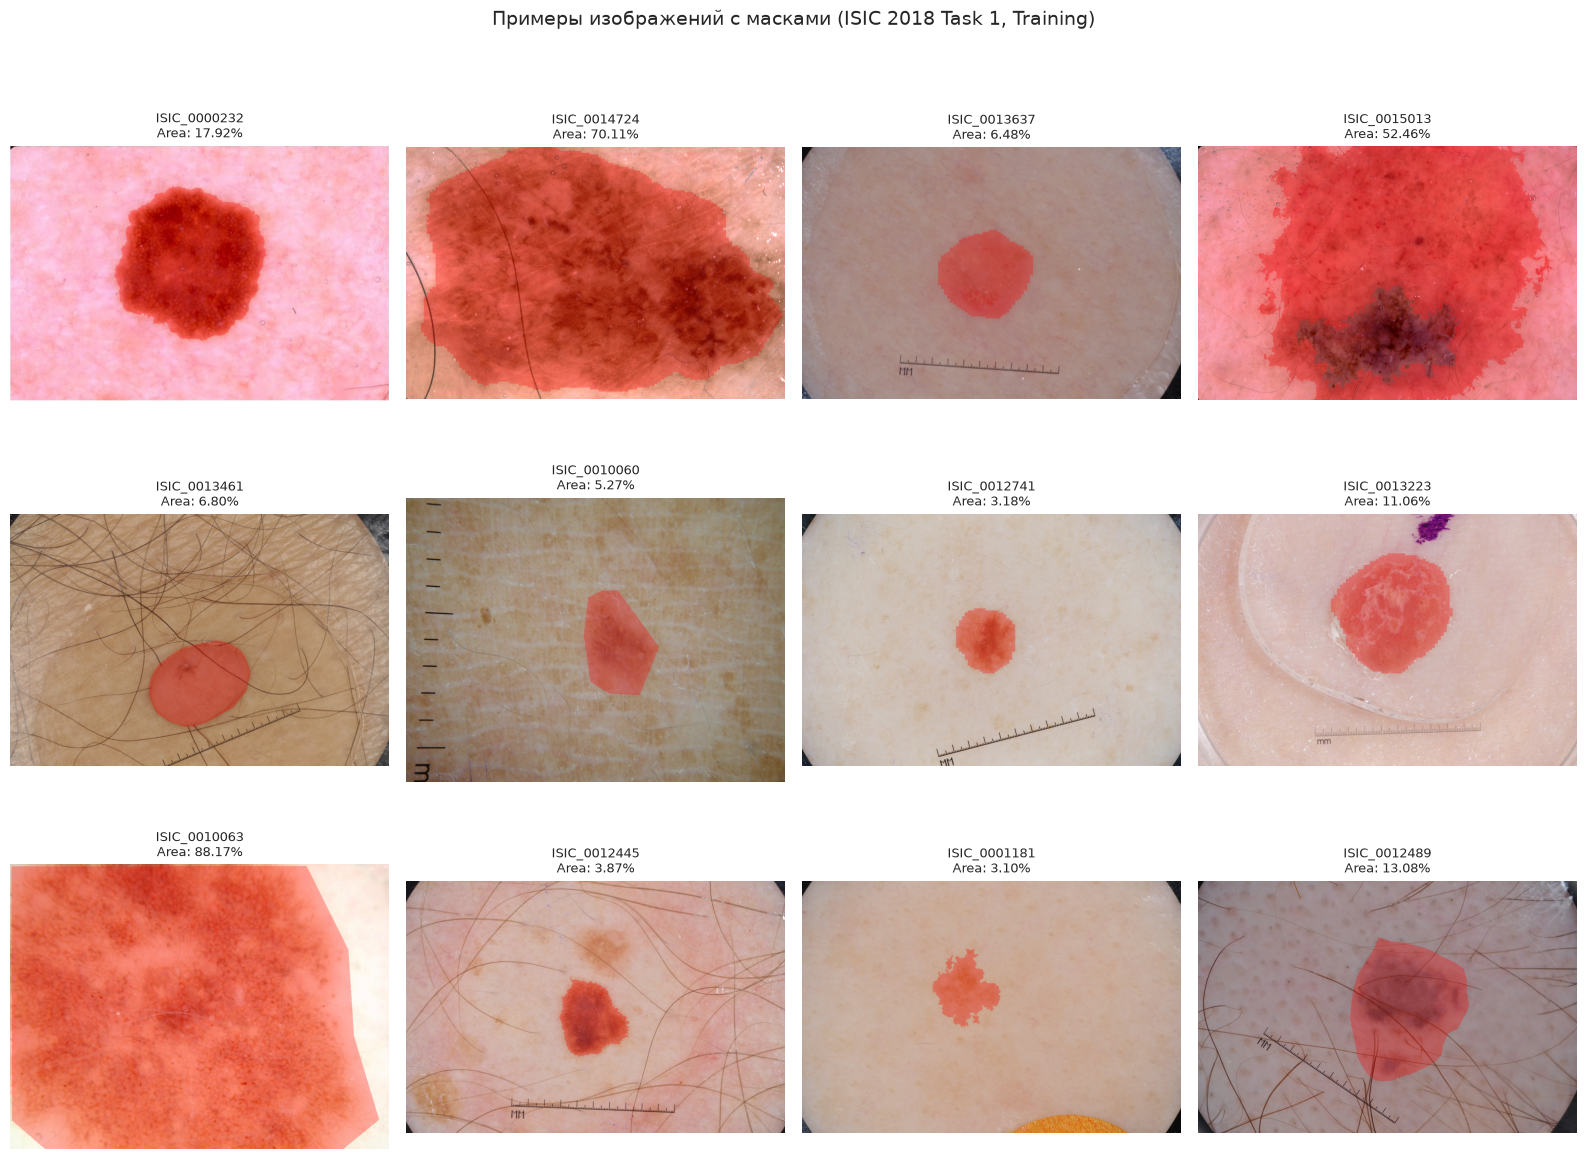

In [53]:
# Визуализация примеров изображений с масками
n_samples = 12
sample_df = df_train.sample(n=min(n_samples, len(df_train)), random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for idx, (_, row) in enumerate(sample_df.iterrows()):
    img = cv2.imread(row['img_path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row['mask_path'], cv2.IMREAD_GRAYSCALE)
    
    # Overlay mask
    overlay = img.copy()
    overlay[mask > 127] = [255, 0, 0]  # Red overlay
    blended = cv2.addWeighted(img, 0.7, overlay, 0.3, 0)
    
    axes[idx].imshow(blended)
    axes[idx].set_title(f"{row['file_stem']}\nArea: {row['mask_area_ratio']:.2%}", fontsize=9)
    axes[idx].axis('off')

plt.suptitle('Примеры изображений с масками (ISIC 2018 Task 1, Training)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('train_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 7️⃣ Распределения ключевых метрик

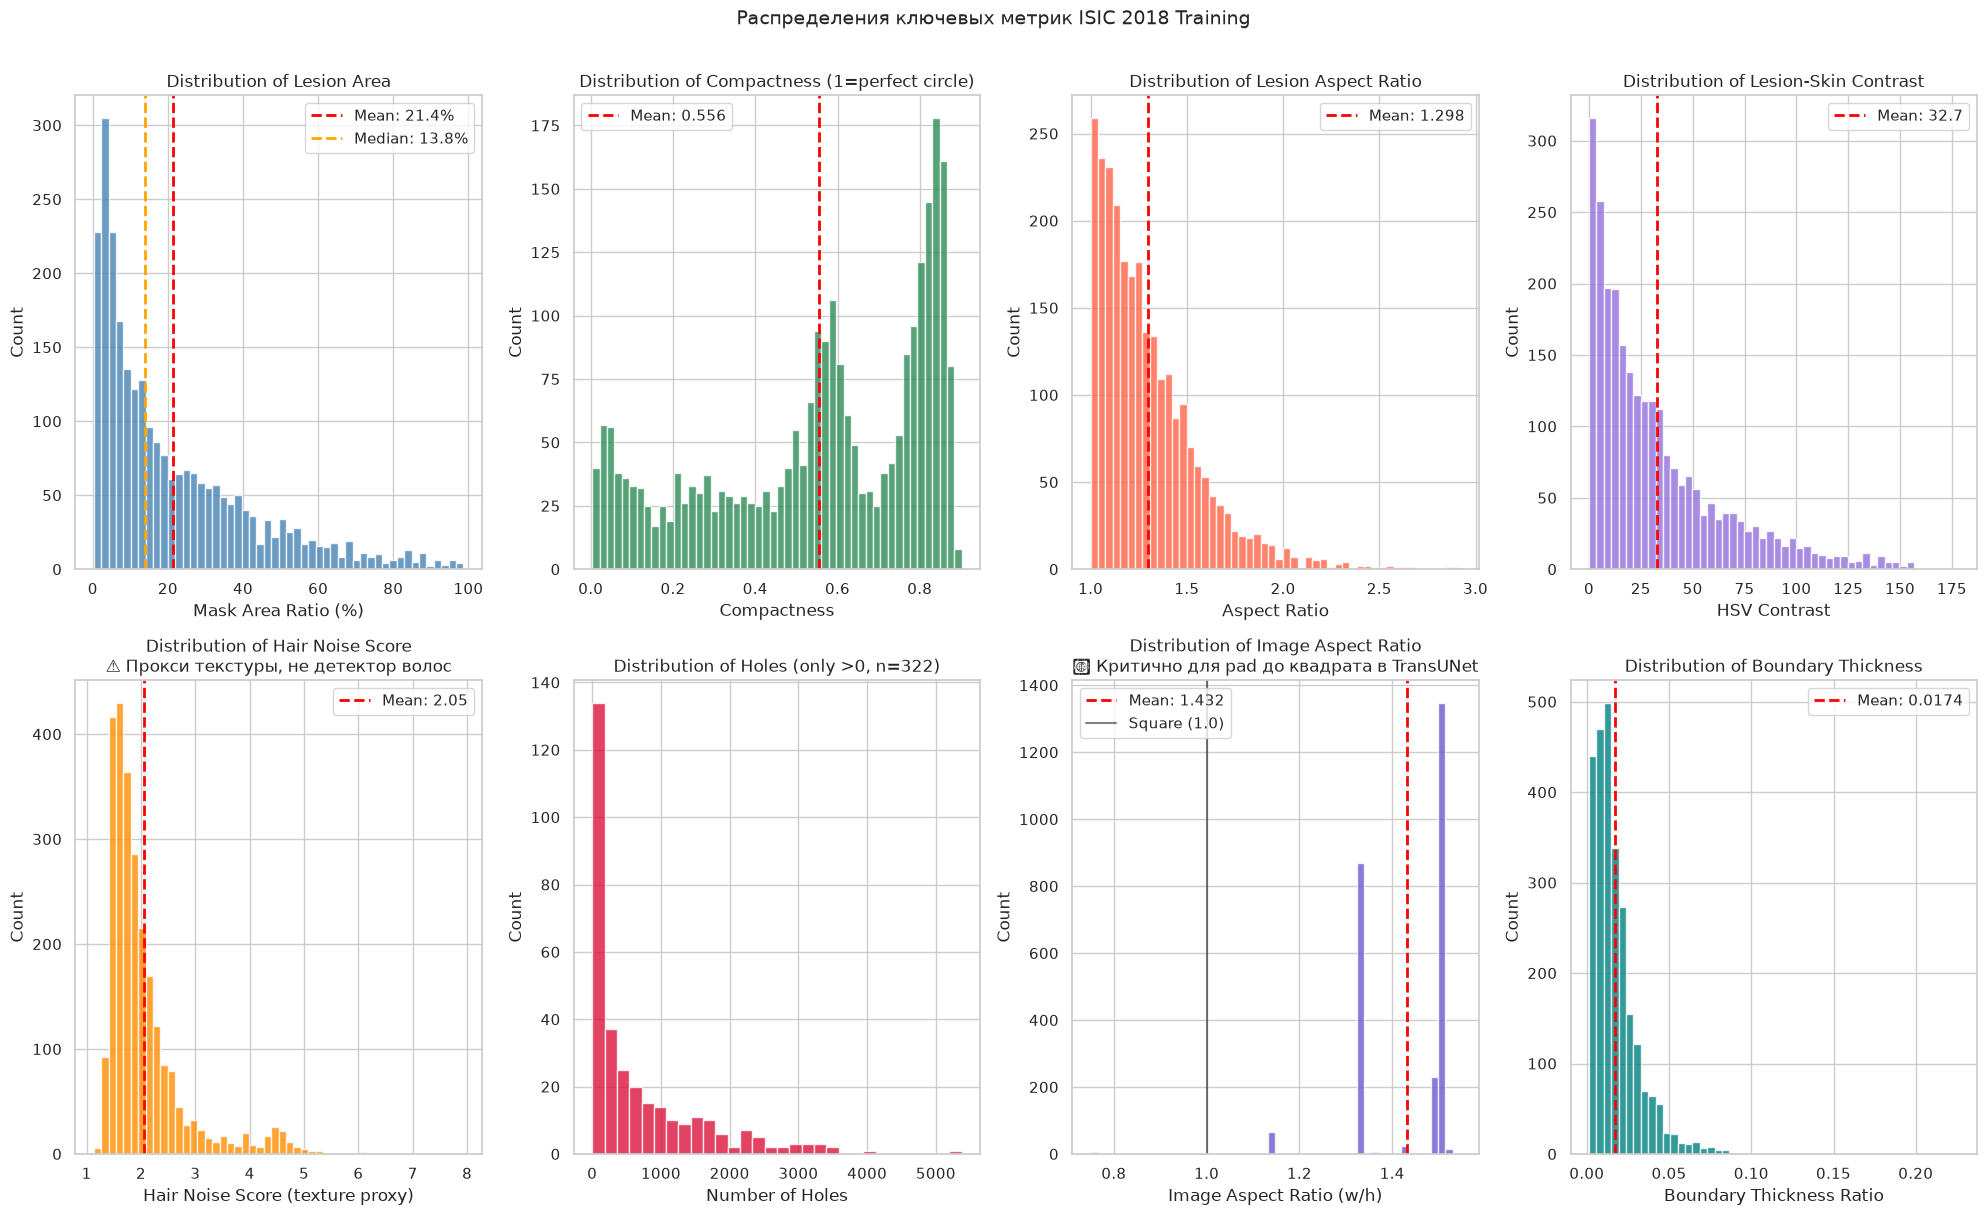

In [54]:
fig, axes = plt.subplots(2, 4, figsize=(20, 12))

# 1. Mask area ratio
axes[0, 0].hist(valid_masks['mask_area_ratio'] * 100, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[0, 0].axvline(valid_masks['mask_area_ratio'].mean() * 100, color='red', linestyle='--', linewidth=2, label=f'Mean: {valid_masks["mask_area_ratio"].mean()*100:.1f}%')
axes[0, 0].axvline(valid_masks['mask_area_ratio'].median() * 100, color='orange', linestyle='--', linewidth=2, label=f'Median: {valid_masks["mask_area_ratio"].median()*100:.1f}%')
axes[0, 0].set_xlabel('Mask Area Ratio (%)')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_title('Distribution of Lesion Area')
axes[0, 0].legend()

# 2. Compactness
axes[0, 1].hist(valid_masks['compactness'], bins=50, color='seagreen', edgecolor='white', alpha=0.8)
axes[0, 1].axvline(valid_masks['compactness'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {valid_masks["compactness"].mean():.3f}')
axes[0, 1].set_xlabel('Compactness')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title('Distribution of Compactness (1=perfect circle)')
axes[0, 1].legend()

# 3. Lesion aspect ratio
axes[0, 2].hist(valid_masks['lesion_aspect_ratio'], bins=50, color='tomato', edgecolor='white', alpha=0.8)
axes[0, 2].axvline(valid_masks['lesion_aspect_ratio'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {valid_masks["lesion_aspect_ratio"].mean():.3f}')
axes[0, 2].set_xlabel('Aspect Ratio')
axes[0, 2].set_ylabel('Count')
axes[0, 2].set_title('Distribution of Lesion Aspect Ratio')
axes[0, 2].legend()

# 4. Lesion-skin contrast
axes[0, 3].hist(valid_masks['lesion_skin_contrast'], bins=50, color='mediumpurple', edgecolor='white', alpha=0.8)
axes[0, 3].axvline(valid_masks['lesion_skin_contrast'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {valid_masks["lesion_skin_contrast"].mean():.1f}')
axes[0, 3].set_xlabel('HSV Contrast')
axes[0, 3].set_ylabel('Count')
axes[0, 3].set_title('Distribution of Lesion-Skin Contrast')
axes[0, 3].legend()

# 5. Hair noise score (прокси текстуры, не детектор волос)
axes[1, 0].hist(valid_masks['hair_noise_score'], bins=50, color='darkorange', edgecolor='white', alpha=0.8)
axes[1, 0].axvline(valid_masks['hair_noise_score'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {valid_masks["hair_noise_score"].mean():.2f}')
axes[1, 0].set_xlabel('Hair Noise Score (texture proxy)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('Distribution of Hair Noise Score\n⚠️ Прокси текстуры, не детектор волос')
axes[1, 0].legend()

# 6. N holes (log scale)
holes_data = valid_masks[valid_masks['n_holes'] > 0]['n_holes']
axes[1, 1].hist(holes_data, bins=30, color='crimson', edgecolor='white', alpha=0.8)
axes[1, 1].set_xlabel('Number of Holes')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title(f'Distribution of Holes (only >0, n={len(holes_data)})')

# 7. 🆕 Image aspect ratio distribution (критично для TransUNet)
axes[1, 2].hist(df_train['aspect_ratio'], bins=50, color='slateblue', edgecolor='white', alpha=0.8)
axes[1, 2].axvline(df_train['aspect_ratio'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_train["aspect_ratio"].mean():.3f}')
axes[1, 2].axvline(1.0, color='black', linestyle='-', linewidth=1.5, alpha=0.5, label='Square (1.0)')
axes[1, 2].set_xlabel('Image Aspect Ratio (w/h)')
axes[1, 2].set_ylabel('Count')
axes[1, 2].set_title('Distribution of Image Aspect Ratio\n💡 Критично для pad до квадрата в TransUNet')
axes[1, 2].legend()

# 8. 🆕 Boundary thickness ratio
axes[1, 3].hist(valid_masks['boundary_thickness_ratio'], bins=50, color='teal', edgecolor='white', alpha=0.8)
axes[1, 3].axvline(valid_masks['boundary_thickness_ratio'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {valid_masks["boundary_thickness_ratio"].mean():.4f}')
axes[1, 3].set_xlabel('Boundary Thickness Ratio')
axes[1, 3].set_ylabel('Count')
axes[1, 3].set_title('Distribution of Boundary Thickness')
axes[1, 3].legend()

plt.suptitle('Распределения ключевых метрик ISIC 2018 Training', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('train_summary_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 8️⃣ Детектирование дубликатов (simple hash + визуализация)


🔍 Анализ дубликатов (dhash, Hamming ≤ 5 — near-duplicates):
   • Всего изображений: 2594
   • Найдено дубликатных пар: 2
   ⚠️ dhash с Hamming ≤ 5 детектирует near-duplicates (JPEG-рекомпрессия,
        небольшое изменение яркости). Абсолютно идентичные файлы — подмножество.
   • Групп дубликатов: 2
   • Всего дублированных изображений: 4

   • Сохранено в isic2018_train_duplicates.csv

   Примеры дубликатных групп:
     - 2x: ISIC_0012290, ISIC_0013594...
     - 2x: ISIC_0012887, ISIC_0012989...


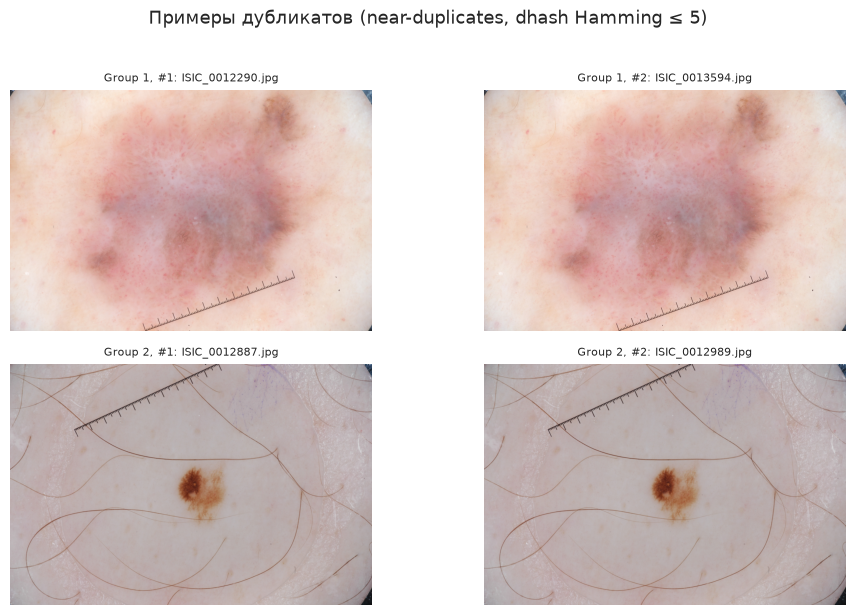


✅ Сохранено: train_duplicates_visualization.png


In [55]:
# Поиск дубликатов по dhash (Hamming distance ≤ 5 — детектирует near-duplicates)
# --- dhash-based duplicate detection with Hamming distance ---
HAMMING_THRESHOLD = 5  # расстояние Хэмминга ≤ 5 → дубликат

dhashes = df_train['dhash'].values
n = len(dhashes)
dup_pairs = []
# Сравниваем попарно (O(n²), но для 2594 изображений приемлемо при 64-битных строках)
for i in range(n):
    for j in range(i + 1, n):
        if (dhashes[i] ^ dhashes[j]).bit_count() <= HAMMING_THRESHOLD:
            dup_pairs.append((i, j))

print(f"\n🔍 Анализ дубликатов (dhash, Hamming ≤ {HAMMING_THRESHOLD} — near-duplicates):")
print(f"   • Всего изображений: {n}")
print(f"   • Найдено дубликатных пар: {len(dup_pairs)}")
print(f"   ⚠️ dhash с Hamming ≤ {HAMMING_THRESHOLD} детектирует near-duplicates (JPEG-рекомпрессия,")
print(f"        небольшое изменение яркости). Абсолютно идентичные файлы — подмножество.")

if len(dup_pairs) > 0:
    # Группировка через union-find
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry:
            parent[rx] = ry
    for i, j in dup_pairs:
        union(i, j)

    # Собираем группы
    groups = {}
    for idx in range(n):
        root = find(idx)
        groups.setdefault(root, []).append(idx)
    dup_groups = {k: v for k, v in groups.items() if len(v) > 1}

    print(f"   • Групп дубликатов: {len(dup_groups)}")
    total_dup = sum(len(g) for g in dup_groups.values())
    print(f"   • Всего дублированных изображений: {total_dup}")

    dup_records = []
    for root, indices in list(dup_groups.items())[:20]:
        stems = df_train.iloc[indices]['file_stem'].tolist()
        dup_records.append({
            'group_id': root,
            'count': len(stems),
            'files': ', '.join(stems)
        })

    dup_df = pd.DataFrame(dup_records)
    dup_df.to_csv('isic2018_train_duplicates.csv', index=False)
    print(f"\n   • Сохранено в isic2018_train_duplicates.csv")
    print(f"\n   Примеры дубликатных групп:")
    for _, row in dup_df.head(10).iterrows():
        print(f"     - {row['count']}x: {row['files'][:100]}...")

    # 🆕 Визуализация примеров дубликатов
    n_dup_groups_to_show = min(4, len(dup_groups))
    dup_roots_to_show = list(dup_groups.keys())[:n_dup_groups_to_show]

    fig, axes = plt.subplots(n_dup_groups_to_show, 2, figsize=(10, 3 * n_dup_groups_to_show))
    if n_dup_groups_to_show == 1:
        axes = axes.reshape(1, -1)

    for row_idx, root in enumerate(dup_roots_to_show):
        dup_group_indices = dup_groups[root]
        dup_imgs = df_train.iloc[dup_group_indices]['img_path'].values
        for col_idx in range(min(2, len(dup_imgs))):
            img = cv2.imread(dup_imgs[col_idx])
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                axes[row_idx, col_idx].imshow(img)
            axes[row_idx, col_idx].set_title(
                f'Group {row_idx+1}, #{col_idx+1}: {os.path.basename(dup_imgs[col_idx])[:40]}',
                fontsize=8
            )
            axes[row_idx, col_idx].axis('off')

    plt.suptitle('Примеры дубликатов (near-duplicates, dhash Hamming ≤ 5)', fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig('train_duplicates_visualization.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\n✅ Сохранено: train_duplicates_visualization.png")
else:
    print("   ✅ Дубликатов не обнаружено.")


## 9️⃣ Summary статистика

In [56]:
# Сводная статистика
summary_cols = ['mask_area_ratio', 'compactness', 'lesion_aspect_ratio', 
                'lesion_skin_contrast', 'hair_noise_score', 'n_holes',
                'boundary_thickness_ratio', 'edge_smoothness', 'edge_mean_gradient']

summary_stats = valid_masks[summary_cols].describe().T
summary_stats['median'] = valid_masks[summary_cols].median()
summary_stats.to_csv('isic2018_train_summary.csv')
print("✅ Сохранено: isic2018_train_summary.csv")
print("\n📊 Сводная статистика:")
print(summary_stats.round(4))

✅ Сохранено: isic2018_train_summary.csv

📊 Сводная статистика:
                           count     mean       std     min     25%      50%  \
mask_area_ratio           2594.0   0.2140    0.2084  0.0030  0.0517   0.1381   
compactness               2594.0   0.5558    0.2644  0.0036  0.3610   0.5952   
lesion_aspect_ratio       2594.0   1.2977    0.2595  1.0000  1.1029   1.2348   
lesion_skin_contrast      2594.0  32.6712   32.2890  0.0112  8.4018  22.3002   
hair_noise_score          2594.0   2.0519    0.7701  1.1338  1.5812   1.8102   
n_holes                   2594.0  86.3180  386.1629  0.0000  0.0000   0.0000   
boundary_thickness_ratio  2594.0   0.0174    0.0144  0.0013  0.0078   0.0137   
edge_smoothness           2594.0  13.5438   15.8442  2.2803  6.4951   9.6057   
edge_mean_gradient        2594.0  14.3687    9.2862  3.0330  8.8606  12.1572   

                              75%        max   median  
mask_area_ratio            0.3187     0.9866   0.1381  
compactness             

---
---
## 🆕 10️⃣ Pixel-Level Class Imbalance (ТОЧНЫЙ ПОДСЧЁТ)

**Критически важно для сегментации!** В отличие от per-image среднего в разделе 5️⃣, здесь считаем **точный глобальный дисбаланс** по всем маскам для настройки:
- `α` параметра для **Focal Loss**
- `pos_weight` для **BCEWithLogitsLoss**
- Class weights для **CrossEntropyLoss**


🎯 PIXEL-LEVEL CLASS IMBALANCE — ТОЧНЫЙ ПОДСЧЁТ


Pixel counting: 100%|██████████| 2594/2594 [00:47<00:00, 54.65it/s] 



📊 ГЛОБАЛЬНАЯ PIXEL-LEVEL СТАТИСТИКА:
   • Всего пикселей (по всем изображениям): 24,102,335,090
   • Foreground пикселей (lesion):  5,452,345,907 (22.62%)
   • Background пикселей (skin):    18,649,989,183 (77.38%)
   • Точный дисбаланс (bg : fg):     3.42 : 1

🔧 ПАРАМЕТРЫ ДЛЯ LOSS FUNCTIONS:
   • α (alpha) для Focal Loss:           0.2262
   • pos_weight для BCEWithLogitsLoss:   3.4205
   • Class weights [bg, fg]:             [0.2262, 0.7738]

📈 PER-IMAGE СТАТИСТИКА (для сравнения):
   • Средний per-image fg ratio:   21.40%
   • Медианный per-image fg ratio: 13.81%
   • Средний дисбаланс (per-image): 15.81:1
   ⚠️ Сравните: per-image среднее ≠ глобальный точный подсчёт!

💡 Рекомендации для PyTorch:
   ```python
   # Вариант 1: Focal Loss
   criterion = FocalLoss(alpha=0.2262, gamma=2.0)
   
   # Вариант 2: BCEWithLogitsLoss
   pos_weight = torch.tensor([3.4205])
   criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
   
   # Вариант 3: CrossEntropyLoss
   class_weights = torch.te

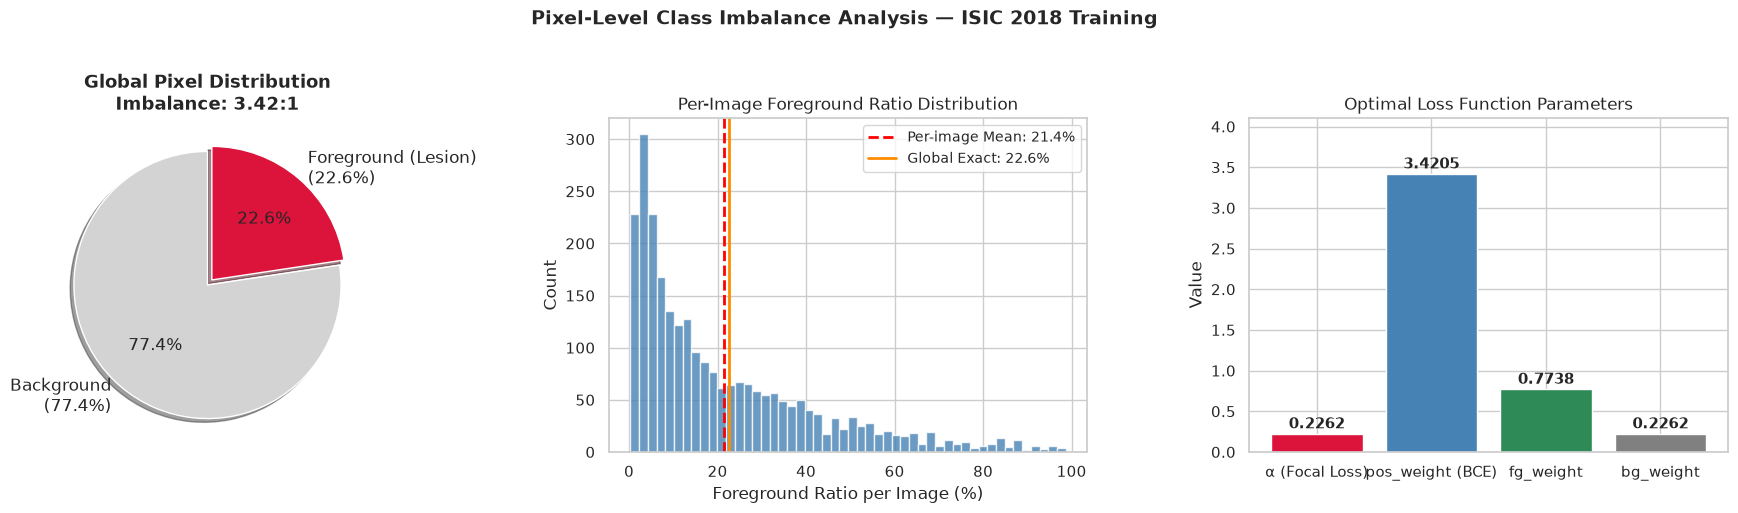


✅ Сохранено: train_pixel_level_imbalance.png


In [57]:
print("\n" + "="*80)
print("🎯 PIXEL-LEVEL CLASS IMBALANCE — ТОЧНЫЙ ПОДСЧЁТ")
print("="*80)

# Точный подсчёт foreground/background пикселей по всем маскам
total_fg_pixels = 0
total_bg_pixels = 0
per_image_fg_ratios = []

for _, row in tqdm(valid_masks.iterrows(), total=len(valid_masks), desc="Pixel counting"):
    mask = cv2.imread(row['mask_path'], cv2.IMREAD_GRAYSCALE)
    if mask is None:
        continue
    fg = int(np.sum(mask > 127))
    bg = int(np.sum(mask <= 127))
    total_fg_pixels += fg
    total_bg_pixels += bg
    per_image_fg_ratios.append(fg / (fg + bg) if (fg + bg) > 0 else 0)

total_pixels_all = total_fg_pixels + total_bg_pixels
exact_imbalance_ratio = total_bg_pixels / total_fg_pixels

# Параметры для loss functions
alpha_focal = total_fg_pixels / total_pixels_all  # α для Focal Loss (вес foreground)
pos_weight_bce = total_bg_pixels / total_fg_pixels   # pos_weight для BCEWithLogitsLoss
fg_weight = total_bg_pixels / total_pixels_all       # вес foreground класса
bg_weight = total_fg_pixels / total_pixels_all       # вес background класса

print(f"\n📊 ГЛОБАЛЬНАЯ PIXEL-LEVEL СТАТИСТИКА:")
print(f"   • Всего пикселей (по всем изображениям): {total_pixels_all:,}")
print(f"   • Foreground пикселей (lesion):  {total_fg_pixels:,} ({total_fg_pixels/total_pixels_all*100:.2f}%)")
print(f"   • Background пикселей (skin):    {total_bg_pixels:,} ({total_bg_pixels/total_pixels_all*100:.2f}%)")
print(f"   • Точный дисбаланс (bg : fg):     {exact_imbalance_ratio:.2f} : 1")

print(f"\n🔧 ПАРАМЕТРЫ ДЛЯ LOSS FUNCTIONS:")
print(f"   • α (alpha) для Focal Loss:           {alpha_focal:.4f}")
print(f"   • pos_weight для BCEWithLogitsLoss:   {pos_weight_bce:.4f}")
print(f"   • Class weights [bg, fg]:             [{bg_weight:.4f}, {fg_weight:.4f}]")

print(f"\n📈 PER-IMAGE СТАТИСТИКА (для сравнения):")
print(f"   • Средний per-image fg ratio:   {np.mean(per_image_fg_ratios)*100:.2f}%")
print(f"   • Медианный per-image fg ratio: {np.median(per_image_fg_ratios)*100:.2f}%")
print(f"   • Средний дисбаланс (per-image): {np.mean([(1-r)/r for r in per_image_fg_ratios if r > 0]):.2f}:1")
print(f"   ⚠️ Сравните: per-image среднее ≠ глобальный точный подсчёт!")

print(f"\n💡 Рекомендации для PyTorch:")
print(f"   ```python")
print(f"   # Вариант 1: Focal Loss")
print(f"   criterion = FocalLoss(alpha={alpha_focal:.4f}, gamma=2.0)")
print(f"   ")
print(f"   # Вариант 2: BCEWithLogitsLoss")
print(f"   pos_weight = torch.tensor([{pos_weight_bce:.4f}])")
print(f"   criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)")
print(f"   ")
print(f"   # Вариант 3: CrossEntropyLoss")
print(f"   class_weights = torch.tensor([{bg_weight:.4f}, {fg_weight:.4f}])")
print(f"   criterion = nn.CrossEntropyLoss(weight=class_weights)")
print(f"   ```")

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie chart: global pixel distribution
labels = [f'Background\n({total_bg_pixels/total_pixels_all*100:.1f}%)', 
          f'Foreground (Lesion)\n({total_fg_pixels/total_pixels_all*100:.1f}%)']
sizes = [total_bg_pixels, total_fg_pixels]
colors = ['lightgray', 'crimson']
explode = (0, 0.05)
axes[0].pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
            shadow=True, startangle=90, textprops={'fontsize': 12})
axes[0].set_title(f'Global Pixel Distribution\nImbalance: {exact_imbalance_ratio:.2f}:1', fontsize=13, fontweight='bold')

# Bar chart: per-image fg ratio distribution
axes[1].hist(np.array(per_image_fg_ratios) * 100, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(np.mean(per_image_fg_ratios) * 100, color='red', linestyle='--', linewidth=2, 
                label=f'Per-image Mean: {np.mean(per_image_fg_ratios)*100:.1f}%')
axes[1].axvline(total_fg_pixels/total_pixels_all * 100, color='darkorange', linestyle='-', linewidth=2,
                label=f'Global Exact: {total_fg_pixels/total_pixels_all*100:.1f}%')
axes[1].set_xlabel('Foreground Ratio per Image (%)')
axes[1].set_ylabel('Count')
axes[1].set_title('Per-Image Foreground Ratio Distribution')
axes[1].legend(fontsize=10)

# Bar: loss parameters comparison
param_names = ['α (Focal Loss)', 'pos_weight (BCE)', 'fg_weight', 'bg_weight']
param_values = [alpha_focal, pos_weight_bce, fg_weight, bg_weight]
bars = axes[2].bar(param_names, param_values, color=['crimson', 'steelblue', 'seagreen', 'gray'])
for bar, val in zip(bars, param_values):
    axes[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02, f'{val:.4f}',
                 ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[2].set_ylabel('Value')
axes[2].set_title('Optimal Loss Function Parameters')
axes[2].set_ylim(0, max(param_values) * 1.2)

plt.suptitle('Pixel-Level Class Imbalance Analysis — ISIC 2018 Training', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('train_pixel_level_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Сохранено: train_pixel_level_imbalance.png")
print("="*80)

---
---
## 🆕 11️⃣ Multi-Scale Analysis (128, 256, 512)

**Критически важно для TransUNet!** TransUNet имеет 5 уровней энкодера (512→256→128→64→32). Здесь анализируем:
- Сохранность границ (boundary preservation) при downsampling
- Потерю площади (area preservation loss)
- Feature degradation на каждом масштабе
- Рекомендации по оптимальному input size


🔬 MULTI-SCALE ANALYSIS — Boundary & Area Preservation
📂 Загружен кэш multi-scale анализа: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_multiscale_analysis.csv

📊 MULTI-SCALE PRESERVATION STATISTICS (n=200 samples):
   Scale   Kernel    Area Pres.    Boundary Pres.   Area < 0.95   Area Loss %
--------------------------------------------------------------------------------
   512      8     1.0001±0.0016       20.1799±13.5218          0         -0.01%
   256      4     0.9999±0.0032       17.1447±11.5342          0          0.01%
   128      3     1.0021±0.0079       18.1898±12.6309          0         -0.21%


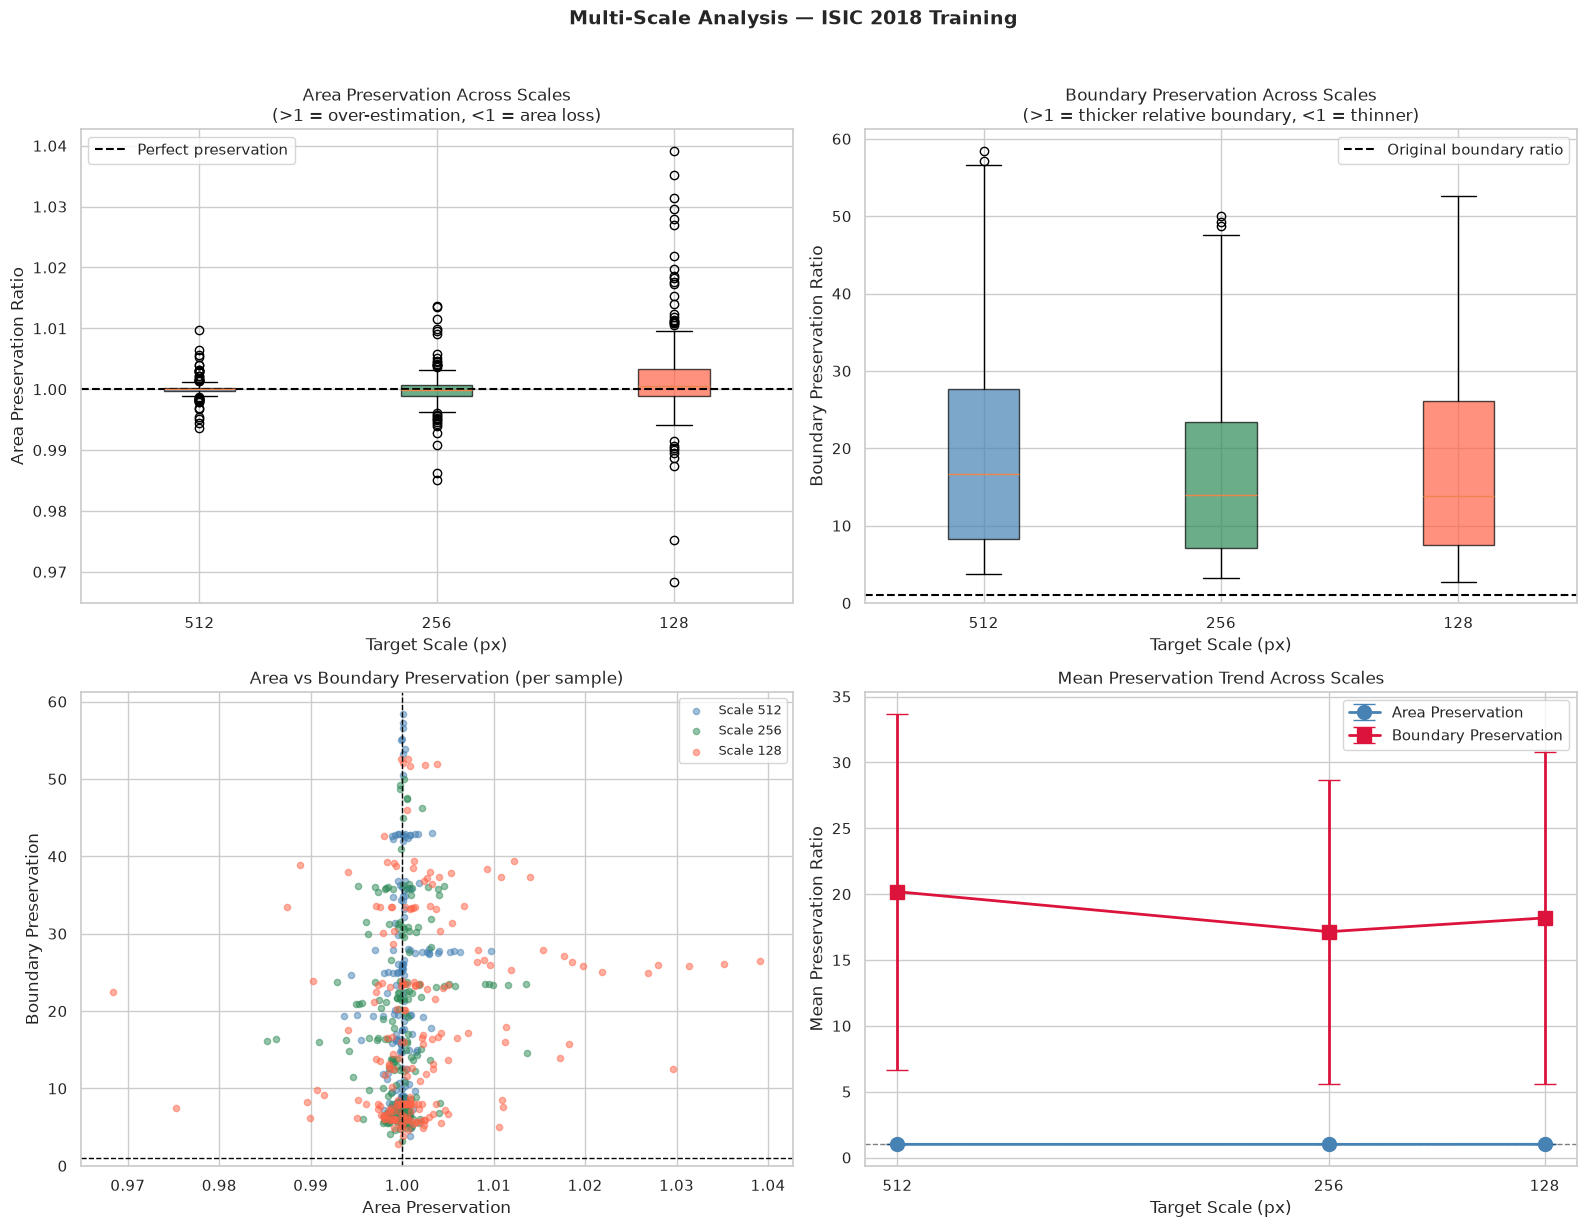


💡 РЕКОМЕНДАЦИИ ПО INPUT SIZE ДЛЯ TransUNet:
   • 512×512: Рекомендуемый размер — минимальная потеря площади и границ
   • 256×256: Приемлемо если ограничены ресурсы, проверьте мелкие поражения (<2%)
   • 128×128: Только для coarse segmentation / detection, НЕ для точной сегментации
   • При ресайзе используйте INTER_AREA для изображений и INTER_NEAREST для масок
   • CSV-кэш: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_multiscale_analysis.csv — при повторных запусках вычисления пропускаются


In [58]:
print("\n" + "="*80)
print("🔬 MULTI-SCALE ANALYSIS — Boundary & Area Preservation")
print("="*80)

# ==========================================
# КЭШИРОВАНИЕ: загружаем CSV если уже вычислено
# ==========================================
MULTISCALE_CSV = CACHE_MULTISCALE  # из конфигурации кэширования
scales = [512, 256, 128]

if os.path.exists(MULTISCALE_CSV):
    print(f"📂 Загружен кэш multi-scale анализа: {MULTISCALE_CSV}")
    df_multi = pd.read_csv(MULTISCALE_CSV)
else:
    n_samples_multi = min(200, len(valid_masks))  # анализируем до 200 случайных примеров
    sample_indices = rng.sample(range(len(valid_masks)), n_samples_multi)

    multi_scale_results = []

    for idx in tqdm(sample_indices, desc="Multi-scale analysis"):
        row = valid_masks.iloc[idx]
        mask = cv2.imread(row['mask_path'], cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue

        h, w = mask.shape
        original_area = np.sum(mask > 127)

        # Оригинальные boundary пиксели (на полном разрешении)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        orig_bin = (mask > 127).astype(np.uint8)
        orig_boundary = cv2.dilate(orig_bin, kernel, iterations=1) - cv2.erode(orig_bin, kernel, iterations=1)
        orig_boundary_pixels = np.sum(orig_boundary > 0)

        for scale in scales:
            # Ресайз маски до фиксированного scale (сохраняя пропорции, pad до квадрата)
            scale_factor = scale / max(h, w)
            new_h, new_w = int(h * scale_factor), int(w * scale_factor)

            mask_resized = cv2.resize(mask, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
            resized_area = np.sum(mask_resized > 127)

            # 🆕 Адаптивный kernel: масштабируется под размер изображения
            ks = max(3, min(scale // 64, 9))
            kernel_scaled = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ks, ks))

            # Boundary на ресайзнутой маске
            resized_bin = (mask_resized > 127).astype(np.uint8)
            resized_boundary = cv2.dilate(resized_bin, kernel_scaled, iterations=1) - cv2.erode(resized_bin, kernel_scaled, iterations=1)
            resized_boundary_pixels = np.sum(resized_boundary > 0)

            # Area preservation: отношение площади после ресайза к оригиналу (с учётом масштаба)
            area_scale = (new_h * new_w) / (h * w)
            expected_area = original_area * area_scale
            area_preservation = resized_area / expected_area if expected_area > 0 else 1.0

            # Boundary preservation: отношение boundary/area на данном масштабе
            boundary_to_area = resized_boundary_pixels / resized_area if resized_area > 0 else 0
            orig_boundary_to_area = orig_boundary_pixels / original_area if original_area > 0 else 0
            boundary_preservation = boundary_to_area / orig_boundary_to_area if orig_boundary_to_area > 0 else 1.0

            multi_scale_results.append({
                'file_stem': row['file_stem'],
                'scale': scale,
                'kernel_size': ks,
                'area_preservation': area_preservation,
                'boundary_preservation': boundary_preservation,
                'orig_area_px': original_area,
                'resized_area_px': resized_area,
                'orig_boundary_px': orig_boundary_pixels,
                'resized_boundary_px': resized_boundary_pixels,
            })

    df_multi = pd.DataFrame(multi_scale_results)

    # Сохраняем в CSV для будущих запусков
    save_cache(df_multi, CACHE_MULTISCALE, format='csv')
    print(f"💾 Кэш сохранён: {MULTISCALE_CSV}")

# Статистика по масштабам
print(f"\n📊 MULTI-SCALE PRESERVATION STATISTICS (n={df_multi['file_stem'].nunique()} samples):")
print(f"{'Scale':>8s}  {'Kernel':>7s}  {'Area Pres.':>12s}  {'Boundary Pres.':>16s}  {'Area < 0.95':>12s}  {'Area Loss %':>12s}")
print("-" * 80)
for scale in scales:
    subset = df_multi[df_multi['scale'] == scale]
    area_mean = subset['area_preservation'].mean()
    area_std = subset['area_preservation'].std()
    bound_mean = subset['boundary_preservation'].mean()
    bound_std = subset['boundary_preservation'].std()
    area_bad = (subset['area_preservation'] < 0.95).sum()
    area_loss = (1 - area_mean) * 100
    ks_used = subset['kernel_size'].iloc[0] if 'kernel_size' in subset.columns else 3
    print(f"  {scale:4d}   {ks_used:4d}    {area_mean:7.4f}±{area_std:.4f}   {bound_mean:11.4f}±{bound_std:.4f}   {area_bad:8d}      {area_loss:8.2f}%")

# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Area preservation distribution per scale (boxplot)
area_data = [df_multi[df_multi['scale'] == s]['area_preservation'].values for s in scales]
bp1 = axes[0, 0].boxplot(area_data, tick_labels=[str(s) for s in scales], patch_artist=True)
for patch, color in zip(bp1['boxes'], ['steelblue', 'seagreen', 'tomato']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0, 0].axhline(y=1.0, color='black', linestyle='--', linewidth=1.5, label='Perfect preservation')
axes[0, 0].set_ylabel('Area Preservation Ratio')
axes[0, 0].set_xlabel('Target Scale (px)')
axes[0, 0].set_title('Area Preservation Across Scales\n(>1 = over-estimation, <1 = area loss)')
axes[0, 0].legend()

# 2. Boundary preservation per scale
bound_data = [df_multi[df_multi['scale'] == s]['boundary_preservation'].values for s in scales]
bp2 = axes[0, 1].boxplot(bound_data, tick_labels=[str(s) for s in scales], patch_artist=True)
for patch, color in zip(bp2['boxes'], ['steelblue', 'seagreen', 'tomato']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0, 1].axhline(y=1.0, color='black', linestyle='--', linewidth=1.5, label='Original boundary ratio')
axes[0, 1].set_ylabel('Boundary Preservation Ratio')
axes[0, 1].set_xlabel('Target Scale (px)')
axes[0, 1].set_title('Boundary Preservation Across Scales\n(>1 = thicker relative boundary, <1 = thinner)')
axes[0, 1].legend()

# 3. Scatter: area vs boundary preservation colored by scale
colors = ['steelblue', 'seagreen', 'tomato']
for scale, color in zip(scales, colors):
    subset = df_multi[df_multi['scale'] == scale]
    axes[1, 0].scatter(subset['area_preservation'], subset['boundary_preservation'],
                       c=color, alpha=0.5, s=20, label=f'Scale {scale}')
axes[1, 0].axhline(y=1.0, color='black', linestyle='--', linewidth=1)
axes[1, 0].axvline(x=1.0, color='black', linestyle='--', linewidth=1)
axes[1, 0].set_xlabel('Area Preservation')
axes[1, 0].set_ylabel('Boundary Preservation')
axes[1, 0].set_title('Area vs Boundary Preservation (per sample)')
axes[1, 0].legend(fontsize=9)

# 4. Mean preservation trend line
mean_area = [df_multi[df_multi['scale'] == s]['area_preservation'].mean() for s in scales]
mean_bound = [df_multi[df_multi['scale'] == s]['boundary_preservation'].mean() for s in scales]
std_area = [df_multi[df_multi['scale'] == s]['area_preservation'].std() for s in scales]
std_bound = [df_multi[df_multi['scale'] == s]['boundary_preservation'].std() for s in scales]

ax2 = axes[1, 1]
ax2.errorbar(scales, mean_area, yerr=std_area, marker='o', linewidth=2, markersize=10,
             capsize=8, color='steelblue', label='Area Preservation')
ax2.errorbar(scales, mean_bound, yerr=std_bound, marker='s', linewidth=2, markersize=10,
             capsize=8, color='crimson', label='Boundary Preservation')
ax2.axhline(y=1.0, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_xlabel('Target Scale (px)')
ax2.set_ylabel('Mean Preservation Ratio')
ax2.set_title('Mean Preservation Trend Across Scales')
ax2.legend()
ax2.set_xticks(scales)
ax2.invert_xaxis()  # от крупного к мелкому

plt.suptitle('Multi-Scale Analysis — ISIC 2018 Training', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('train_multiscale_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Рекомендации
print(f"\n💡 РЕКОМЕНДАЦИИ ПО INPUT SIZE ДЛЯ TransUNet:")
print(f"   • 512×512: Рекомендуемый размер — минимальная потеря площади и границ")
print(f"   • 256×256: Приемлемо если ограничены ресурсы, проверьте мелкие поражения (<2%)")
print(f"   • 128×128: Только для coarse segmentation / detection, НЕ для точной сегментации")
print(f"   • При ресайзе используйте INTER_AREA для изображений и INTER_NEAREST для масок")
print(f"   • CSV-кэш: {MULTISCALE_CSV} — при повторных запусках вычисления пропускаются")

print("="*80)


---
---
## 🆕 12️⃣ Hard Examples Mining (4 критерия + CSV экспорт)

**Критически важно для обучения!** Выявляем сложные случаи, которые будут определять потолок качества модели:
1. **Tiny lesion + низкий контраст** — легко потерять
2. **Касание границ + нерегулярная форма** — partial context
3. **Высокий hair noise (прокси текстуры) + низкий контраст** — шум маскирует границы
4. **Размытые/грубые границы** — boundary ambiguity

> ⚠️ Критерий 3 использует `hair_noise_score` — **прокси** текстуры изображения, а не детектор волос.
> Для точного hair removal используйте DullRazor или морфологический метод.


🔍 HARD EXAMPLES MINING — 4 критерия сложности

📊 HARD EXAMPLES STATISTICS:
   • Всего изображений в training:    2594
   • Выявлено сложных случаев:        774 (29.8%)

   По критериям:
   1️⃣ Tiny lesion + low contrast:        78 (3.0%)
      → Площадь < 2% И контраст < 22.3 (медиана)
   2️⃣ Border touching + irregular:       79 (3.0%)
      → Касание границ И compactness < 0.361 (Q25)
   3️⃣ High texture noise + low contrast:  271 (10.4%)
      → Texture score > 2.2 (Q75, прокси волос) И контраст < 22.3
   4️⃣ Rough/blurry boundaries:          519 (20.0%)
      → Edge smoothness > 17.0352 (Q80)
💾 Кэш сохранён: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_hard_examples.csv

✅ Сохранено: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2018_hard_examples.csv (774 записей)


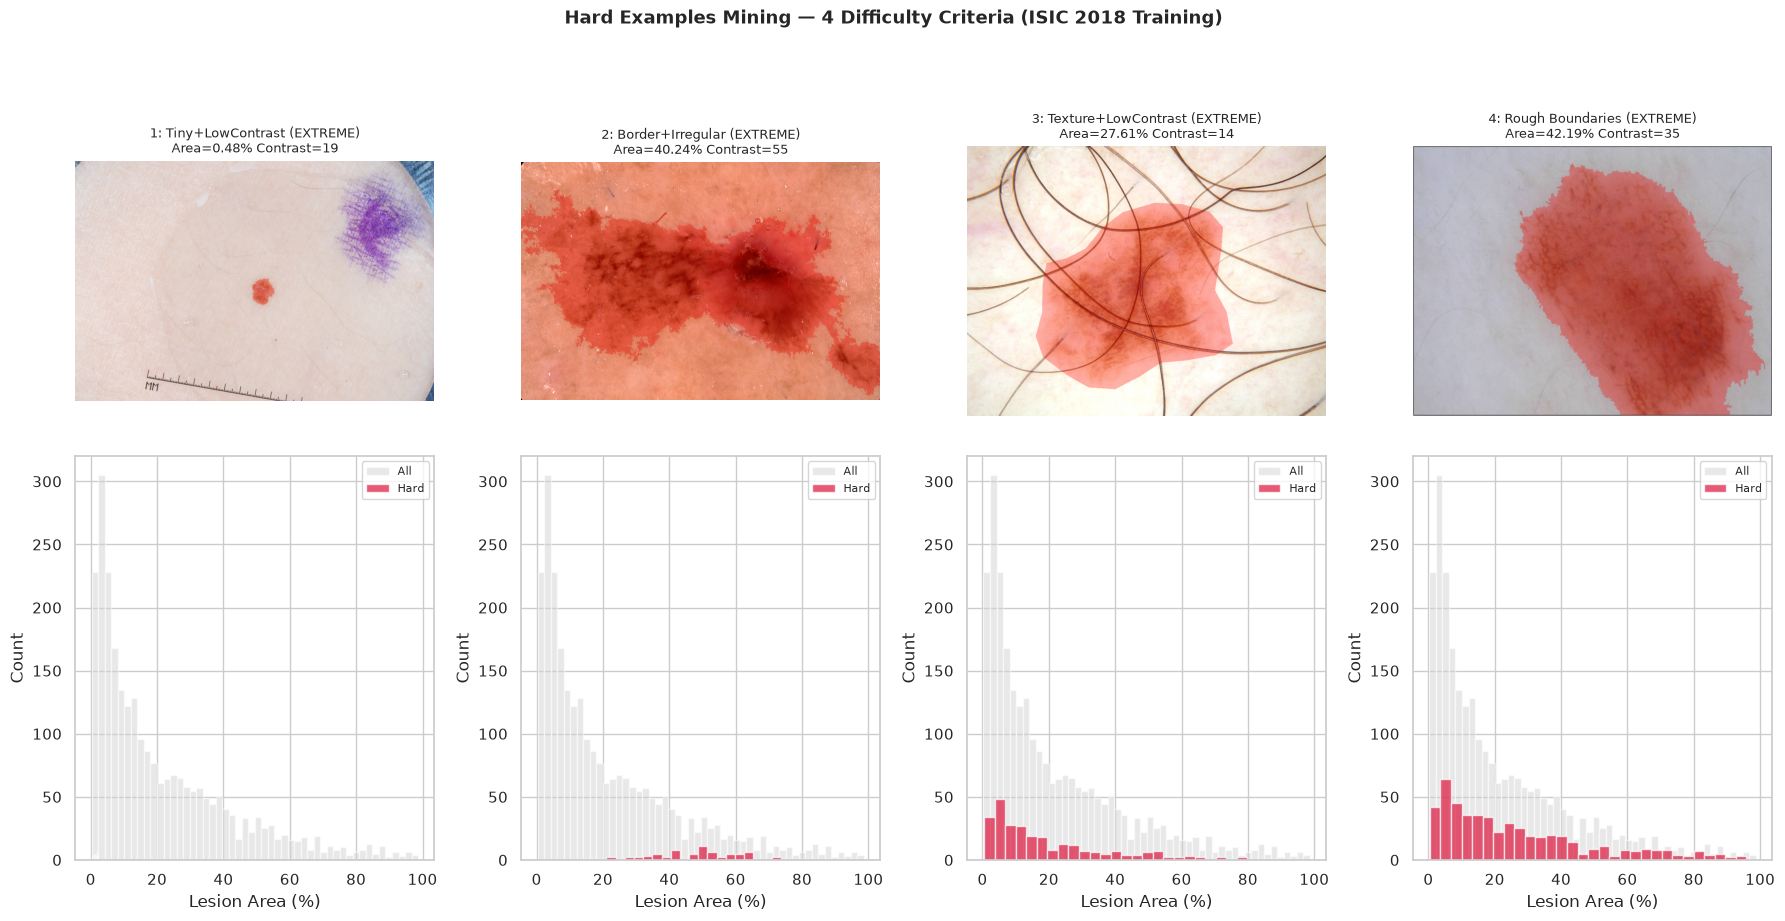


✅ Сохранено: train_hard_examples.png

💡 РЕКОМЕНДАЦИИ ПО HARD EXAMPLES:
   1. Для критерия 1 (tiny lesions): использовать augmentation с zoom-in
   2. Для критерия 2 (border touching): добавить padding / mirroring
   3. Для критерия 3 (texture noise/hair proxy): применить hair removal preprocessing (DullRazor) или augmentations с размытием
   4. Для критерия 4 (rough boundaries): увеличить вес boundary loss (Boundary IoU)
   5. Рекомендуется oversampling hard examples в DataLoader (x2-x3)
   ⚠️ Критерий 3 основан на прокси-метрике текстуры, не детекторе волос. См. раздел 5️⃣.


In [59]:
print("\n" + "="*80)
print("🔍 HARD EXAMPLES MINING — 4 критерия сложности")
print("="*80)

# Определяем пороги на основе распределений
contrast_median = valid_masks['lesion_skin_contrast'].median()
area_small_threshold = 0.02  # <2% площади — очень маленькое поражение
compactness_low = valid_masks['compactness'].quantile(0.25)  # нижний квартиль
hair_high = valid_masks['hair_noise_score'].quantile(0.75)  # верхний квартиль
edge_smoothness_high = valid_masks['edge_smoothness'].quantile(0.80)  # негладкие границы

# Критерий 1: Малое поражение + низкий контраст
hard_crit1 = valid_masks[
    (valid_masks['mask_area_ratio'] < area_small_threshold) &
    (valid_masks['lesion_skin_contrast'] < contrast_median)
].copy()
hard_crit1['hard_reason'] = 'tiny_lesion_low_contrast'

# Критерий 2: Касание границ + нерегулярная форма
hard_crit2 = valid_masks[
    (valid_masks['touches_border'] == 1) &
    (valid_masks['compactness'] < compactness_low)
].copy()
hard_crit2['hard_reason'] = 'border_touching_irregular_shape'

# Критерий 3: Высокий уровень текстуры/шума (прокси волос) + низкий контраст
hard_crit3 = valid_masks[
    (valid_masks['hair_noise_score'] > hair_high) &
    (valid_masks['lesion_skin_contrast'] < contrast_median)
].copy()
hard_crit3['hard_reason'] = 'high_texture_noise_low_contrast'

# Критерий 4: Размытые/негладкие границы (высокий edge_smoothness = неровные края)
hard_crit4 = valid_masks[
    (valid_masks['edge_smoothness'] > edge_smoothness_high)
].copy()
hard_crit4['hard_reason'] = 'rough_blurry_boundaries'

# Объединяем все hard examples (дедупликация по file_stem с агрегацией причин)
hard_frames = [hard_crit1, hard_crit2, hard_crit3, hard_crit4]
hard_all = pd.concat(hard_frames, ignore_index=True)
# Агрегируем hard_reason: если один пример попал в несколько критериев — объединяем через ' | '
hard_all = hard_all.groupby('file_stem', as_index=False).agg({
    **{col: 'first' for col in hard_all.columns if col not in ('file_stem', 'hard_reason')},
    'hard_reason': lambda x: ' | '.join(x)
})

# Колонки для экспорта
hard_export_cols = ['file_stem', 'mask_area_ratio', 'lesion_skin_contrast', 'compactness',
                    'hair_noise_score', 'touches_border', 'n_holes', 'edge_smoothness',
                    'boundary_thickness_ratio', 'hard_reason', 'img_path', 'mask_path']

print(f"\n📊 HARD EXAMPLES STATISTICS:")
print(f"   • Всего изображений в training:    {len(valid_masks)}")
print(f"   • Выявлено сложных случаев:        {len(hard_all)} ({len(hard_all)/len(valid_masks)*100:.1f}%)")
print(f"")
print(f"   По критериям:")
print(f"   1️⃣ Tiny lesion + low contrast:      {len(hard_crit1):4d} ({len(hard_crit1)/len(valid_masks)*100:.1f}%)")
print(f"      → Площадь < {area_small_threshold*100:.0f}% И контраст < {contrast_median:.1f} (медиана)")
print(f"   2️⃣ Border touching + irregular:     {len(hard_crit2):4d} ({len(hard_crit2)/len(valid_masks)*100:.1f}%)")
print(f"      → Касание границ И compactness < {compactness_low:.3f} (Q25)")
print(f"   3️⃣ High texture noise + low contrast: {len(hard_crit3):4d} ({len(hard_crit3)/len(valid_masks)*100:.1f}%)")
print(f"      → Texture score > {hair_high:.1f} (Q75, прокси волос) И контраст < {contrast_median:.1f}")
print(f"   4️⃣ Rough/blurry boundaries:         {len(hard_crit4):4d} ({len(hard_crit4)/len(valid_masks)*100:.1f}%)")
print(f"      → Edge smoothness > {edge_smoothness_high:.4f} (Q80)")

# Сохраняем hard examples в CSV
save_cache(hard_all[hard_export_cols], CACHE_HARD_EXAMPLES, format='csv')
print(f"\n✅ Сохранено: {CACHE_HARD_EXAMPLES} ({len(hard_all)} записей)")

# Визуализация hard examples — показываем top-3 самых экстремальных по каждому критерию
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for crit_idx, (crit_name, crit_df, sort_col) in enumerate([
    ('1: Tiny+LowContrast', hard_crit1, 'mask_area_ratio'),
    ('2: Border+Irregular', hard_crit2, 'compactness'),
    ('3: Texture+LowContrast', hard_crit3, 'hair_noise_score'),
    ('4: Rough Boundaries', hard_crit4, 'edge_smoothness')
]):
    ax_img = axes[0, crit_idx]
    ax_dist = axes[1, crit_idx]
    
    if len(crit_df) > 0:
        # 🆕 Показываем самый экстремальный пример (а не случайный)
        ascending = (sort_col == 'mask_area_ratio') or (sort_col == 'compactness')
        extreme_row = crit_df.sort_values(sort_col, ascending=ascending).iloc[0]
        img = cv2.imread(extreme_row['img_path'])
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            mask = cv2.imread(extreme_row['mask_path'], cv2.IMREAD_GRAYSCALE)
            if mask is not None:
                overlay = img.copy()
                overlay[mask > 127] = [255, 0, 0]
                blended = cv2.addWeighted(img, 0.7, overlay, 0.3, 0)
                ax_img.imshow(blended)
        ax_img.set_title(f'{crit_name} (EXTREME)\nArea={extreme_row["mask_area_ratio"]:.2%} Contrast={extreme_row["lesion_skin_contrast"]:.0f}',
                         fontsize=9)
    ax_img.axis('off')
    
    # Распределение сложности
    ax_dist.hist(valid_masks['mask_area_ratio'] * 100, bins=50, color='lightgray', edgecolor='white', alpha=0.5, label='All')
    ax_dist.hist(crit_df['mask_area_ratio'] * 100, bins=30, color='crimson', edgecolor='white', alpha=0.7, label='Hard')
    ax_dist.set_xlabel('Lesion Area (%)')
    ax_dist.set_ylabel('Count')
    ax_dist.legend(fontsize=8)

plt.suptitle('Hard Examples Mining — 4 Difficulty Criteria (ISIC 2018 Training)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('train_hard_examples.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Сохранено: train_hard_examples.png")

# 💡 Рекомендации по hard examples
print(f"\n💡 РЕКОМЕНДАЦИИ ПО HARD EXAMPLES:")
print(f"   1. Для критерия 1 (tiny lesions): использовать augmentation с zoom-in")
print(f"   2. Для критерия 2 (border touching): добавить padding / mirroring")
print(f"   3. Для критерия 3 (texture noise/hair proxy): применить hair removal preprocessing (DullRazor) или augmentations с размытием")
print(f"   4. Для критерия 4 (rough boundaries): увеличить вес boundary loss (Boundary IoU)")
print(f"   5. Рекомендуется oversampling hard examples в DataLoader (x2-x3)")
print(f"   ⚠️ Критерий 3 основан на прокси-метрике текстуры, не детекторе волос. См. раздел 5️⃣.")
print("="*80)

---
---
## 13️⃣ Correlation Matrix (Heatmap ключевых метрик)

**Важно для feature engineering!** Выявляем:
- Избыточные метрики (|r| > 0.8 → redundancy)
- Неожиданные корреляции
- Взаимосвязи между геометрией, цветом и качеством границ
- Какие признаки наиболее информативны для характеризации поражений

> ⚠️ Используется Pearson r **без p-value**. При n≈2594 многие слабые корреляции статистически значимы, но практически бесполезны.
> Порог |r| > 0.8 выбран для детекции мультиколлинеарности. Для строгого анализа используйте VIF (Variance Inflation Factor).


🔗 CORRELATION MATRIX — Ключевые метрики


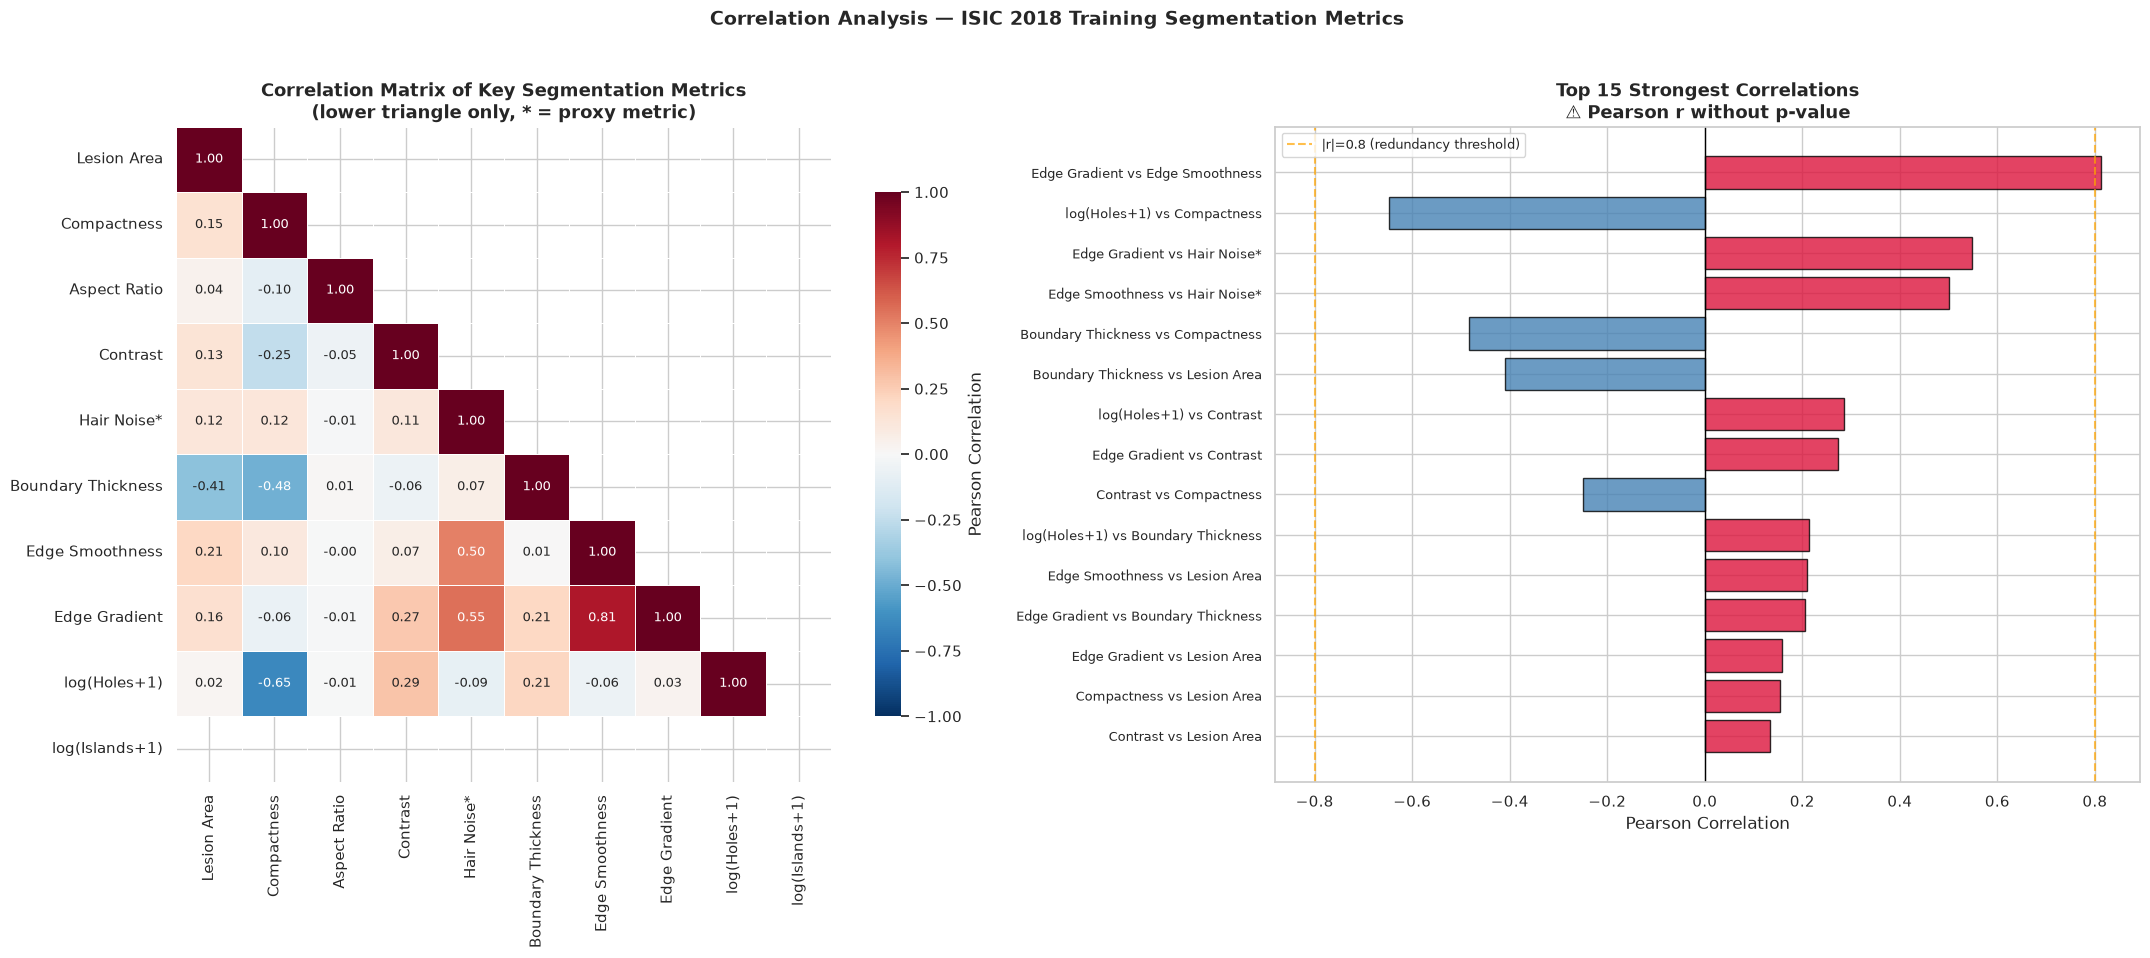


📊 CORRELATION ANALYSIS RESULTS:
   • Всего пар метрик: 45
   • Высокая корреляция (|r| > 0.8): 1 — потенциальная redundancy
   ⚠️ Примечание: используется Pearson r без p-value. При n≈2594 многие слабые
      корреляции статистически значимы, но практически бесполезны. Порог |r| > 0.8
      выбран для детекции мультиколлинеарности. Для строгого анализа используйте VIF.
   • Redundancy pairs:
     - Edge Gradient vs Edge Smoothness: r = 0.812

   🔝 Топ-5 сильнейших корреляций:
     1. Edge Gradient vs Edge Smoothness: r = +0.812 →
     2. log(Holes+1) vs Compactness: r = -0.647 ←
     3. Edge Gradient vs Hair Noise*: r = +0.549 →
     4. Edge Smoothness vs Hair Noise*: r = +0.501 →
     5. Boundary Thickness vs Compactness: r = -0.484 ←

✅ Сохранено: train_correlation_matrix.png
✅ Сохранено: isic2018_correlation_matrix.csv


In [60]:
print("\n" + "="*80)
print("🔗 CORRELATION MATRIX — Ключевые метрики")
print("="*80)

# Выбираем ключевые числовые метрики для корреляционного анализа
corr_cols = [
    'mask_area_ratio',       # Площадь поражения
    'compactness',           # Компактность (1 = идеальный круг)
    'lesion_aspect_ratio',   # Соотношение сторон
    'lesion_skin_contrast',  # Контраст опухоль/кожа
    'hair_noise_score',      # Индекс шума (прокси текстуры)
    'n_holes',               # Количество дырок
    'boundary_thickness_ratio',  # 🆕 Толщина границы
    'edge_smoothness',       # 🆕 Гладкость границ (std градиента)
    'edge_mean_gradient',    # 🆕 Средний градиент на границе
    'noise_islands_count',   # Количество островков шума
]

# Строим корреляционную матрицу
corr_data = valid_masks[corr_cols].copy()
# Логарифмируем n_holes и noise_islands для лучшей корреляции
corr_data['log_n_holes'] = np.log1p(corr_data['n_holes'])
corr_data['log_noise_islands'] = np.log1p(corr_data['noise_islands_count'])

corr_cols_display = [
    'mask_area_ratio', 'compactness', 'lesion_aspect_ratio',
    'lesion_skin_contrast', 'hair_noise_score',
    'boundary_thickness_ratio', 'edge_smoothness', 'edge_mean_gradient',
    'log_n_holes', 'log_noise_islands'
]

corr_matrix = corr_data[corr_cols_display].corr()

# Красивые метки для heatmap
label_map = {
    'mask_area_ratio': 'Lesion Area',
    'compactness': 'Compactness',
    'lesion_aspect_ratio': 'Aspect Ratio',
    'lesion_skin_contrast': 'Contrast',
    'hair_noise_score': 'Hair Noise*',
    'boundary_thickness_ratio': 'Boundary Thickness',
    'edge_smoothness': 'Edge Smoothness',
    'edge_mean_gradient': 'Edge Gradient',
    'log_n_holes': 'log(Holes+1)',
    'log_noise_islands': 'log(Islands+1)',
}

corr_matrix_renamed = corr_matrix.rename(index=label_map, columns=label_map)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# 1. Heatmap корреляционной матрицы
mask = np.triu(np.ones_like(corr_matrix_renamed, dtype=bool), k=1)  # маска для верхнего треугольника
sns.heatmap(corr_matrix_renamed, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation'},
            ax=axes[0], annot_kws={'fontsize': 9})
axes[0].set_title('Correlation Matrix of Key Segmentation Metrics\n(lower triangle only, * = proxy metric)', fontsize=13, fontweight='bold')

# 2. Top correlations barplot
# Извлекаем все уникальные пары (нижний треугольник) и сортируем по |r|
pairs = []
for i in range(len(corr_matrix_renamed.columns)):
    for j in range(i):
        col_i = corr_matrix_renamed.columns[i]
        col_j = corr_matrix_renamed.columns[j]
        val = corr_matrix_renamed.iloc[i, j]
        pairs.append({'pair': f'{col_i} vs {col_j}', 'correlation': val, 'abs_corr': abs(val)})

pairs_df = pd.DataFrame(pairs).sort_values('abs_corr', ascending=False).head(15)
colors_bar = ['crimson' if c > 0 else 'steelblue' for c in pairs_df['correlation']]
axes[1].barh(range(len(pairs_df)), pairs_df['correlation'], color=colors_bar, edgecolor='black', alpha=0.8)
axes[1].set_yticks(range(len(pairs_df)))
axes[1].set_yticklabels(pairs_df['pair'], fontsize=9)
axes[1].axvline(x=0, color='black', linewidth=1)
axes[1].axvline(x=0.8, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='|r|=0.8 (redundancy threshold)')
axes[1].axvline(x=-0.8, color='orange', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Pearson Correlation')
axes[1].set_title('Top 15 Strongest Correlations\n⚠️ Pearson r without p-value', fontsize=13, fontweight='bold')
axes[1].invert_yaxis()
axes[1].legend(fontsize=9)

plt.suptitle('Correlation Analysis — ISIC 2018 Training Segmentation Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('train_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Выводы о redundancy
high_corr_pairs = pairs_df[pairs_df['abs_corr'] > 0.8]
print(f"\n📊 CORRELATION ANALYSIS RESULTS:")
print(f"   • Всего пар метрик: {len(pairs)}")
print(f"   • Высокая корреляция (|r| > 0.8): {len(high_corr_pairs)} — потенциальная redundancy")
print(f"   ⚠️ Примечание: используется Pearson r без p-value. При n≈{len(valid_masks)} многие слабые")
print(f"      корреляции статистически значимы, но практически бесполезны. Порог |r| > 0.8")
print(f"      выбран для детекции мультиколлинеарности. Для строгого анализа используйте VIF.")
if len(high_corr_pairs) > 0:
    print(f"   • Redundancy pairs:")
    for _, row in high_corr_pairs.iterrows():
        print(f"     - {row['pair']}: r = {row['correlation']:.3f}")
else:
    print(f"   • ✅ Нет избыточных метрик (|r| > 0.8) — все признаки информативны")

# Топ-5 сильнейшие корреляции
print(f"\n   🔝 Топ-5 сильнейших корреляций:")
for i, (_, row) in enumerate(pairs_df.head(5).iterrows()):
    direction = '→' if row['correlation'] > 0 else '←'
    print(f"     {i+1}. {row['pair']}: r = {row['correlation']:+.3f} {direction}")

print(f"\n✅ Сохранено: train_correlation_matrix.png")

# Сохраняем матрицу корреляции
corr_matrix_renamed.to_csv('isic2018_correlation_matrix.csv')
print(f"✅ Сохранено: isic2018_correlation_matrix.csv")
print("="*80)

---
---
## 14️⃣ 🚀 ИТОГОВЫЕ РЕКОМЕНДАЦИИ ДЛЯ TransUNet (ОБНОВЛЕННЫЕ)

### 📊 Данные
- 2594 training изображений с масками
- Рекомендуемый input size: **512×512** (оптимальный баланс precision/resources)
- При ресайзе: использовать INTER_AREA для изображений, INTER_NEAREST для масок
- ⚠️ Учитывать долю неквадратных изображений при padding (см. раздел 5️⃣)

### 🎯 Loss Function
- Рекомендуется комбинированная loss: **BCE + Dice Loss** ИЛИ **Focal Loss + Boundary IoU**
- Focal Loss α parameter: **точное значение из раздела 10️⃣**
- BCEWithLogitsLoss pos_weight: **точное значение из раздела 10️⃣**

### 🔬 Аугментации
- **Стандартные:** horizontal flip, rotation (±180°), brightness/contrast
- **Специфичные для ISIC:** hair removal (DullRazor или морфологический), elastic deformation для irregular shapes
- **Hard examples oversampling:** x2-x3 для сложных случаев из раздела 12️⃣

### 🏗️ Архитектура
- TransUNet с boundary refinement module
- Multi-scale supervision на уровнях 512, 256, 128, 64 (основываясь на multi-scale анализе)
- Attention gates на skip connections (помогает с hard examples)

### 📈 Метрики
- **Primary:** Dice score (F1), IoU (Jaccard)
- **Secondary:** Boundary IoU, Hausdorff distance (для оценки качества границ)
- **Monitoring:** per-criteria IoU для hard examples (отслеживать отдельно)

### ⚠️ Ограничения текущего EDA
- `hair_noise_score` — прокси-метрика текстуры, не детектор волос. Для production используйте DullRazor.
- `dhash` — difference hash с порогом Хэмминга ≤ 5. Детектирует near-duplicates (JPEG-рекомпрессия, небольшое изменение яркости). Для попиксельного сравнения используйте `hashlib.md5`.
- ISIC 2018 Task 1 **не предоставляет patient_id** в явном виде. Без patient-aware разбиения возможен data leakage (один пациент может иметь несколько снимков). Рекомендуется: использовать внешние метаданные ISIC 2018 (ISIC Archive) для восстановления patient_id, либо провести визуальную проверку на схожесть снимков.
- Корреляционная матрица: Pearson r без p-value. Для строгого анализа мультиколлинеарности используйте VIF.
- Multi-scale анализ на 200 семплах — репрезентативно, но не исчерпывающе.